# Projet 4 : Étude de santé publique avec Python

#  Analyse de la sécurité alimentaire mondiale (2013-2017)
## Projet d'étude pour la FAO

**Auteur :** Sabah Rizki
    
**Date :** Janvier 2026

**Formation :** Data Analyst

---

###  Contexte du projet

La FAO (Organisation des Nations Unies pour l'alimentation et l'agriculture) cherche à mieux comprendre la répartition des ressources alimentaires mondiales et les problématiques de sous-nutrition.

Ce notebook présente une analyse complète des données FAO sur la période 2013-2017, couvrant :
- La disponibilité alimentaire par pays
- La sous-nutrition dans le monde
- L'aide alimentaire internationale
- Les flux de production et de consommation

###  Objectifs de l'analyse

1. **Quantifier** la sous-nutrition mondiale
2. **Évaluer** les capacités alimentaires théoriques
3. **Identifier** les pays les plus vulnérables
4. **Analyser** l'utilisation des ressources alimentaires
5. **Comprendre** les flux d'aide internationale

---

##  Structure du projet

Ce notebook est organisé en 4 grandes parties :
1. **Importation et préparation** : chargement et nettoyage des données
2. **Exploration** : première découverte des fichiers
3. **Analyses principales** : 11 analyses thématiques
4. **Visualisations** : graphiques et interprétations

---

##  À propos de Jupyter Notebook

Jupyter est l'environnement de référence pour l'analyse de données. Il permet de :
-  Exécuter du code Python par blocs
-  Documenter chaque étape en Markdown
-  Intégrer graphiques et tableaux
-  Partager facilement ses analyses


## Étape 1 : Importation et préparation des données

Cette première étape consiste à charger les outils nécessaires (librairies Python) et à importer les fichiers de données de la FAO.

---

### 1.1 Importation des librairies

Nous utilisons deux librairies Python essentielles pour l'analyse de données :

- **`pandas`** (abrégé pd) : Manipulation de données tabulaires (tableaux, filtres, agrégations)
- **`numpy`**  (abrégé np) : Calculs numériques et opérations mathématiques sur tableaux

Ces outils sont les standards de l'industrie pour l'analyse de données en Python.

In [1009]:
import pandas as pd
import numpy as np

### 1.2 Chargement des fichiers CSV

#### Objectif

Importer les 4 fichiers de données FAO en gérant les problèmes potentiels d'encodage.

#### Méthode de chargement robuste

Les fichiers CSV peuvent présenter des problèmes d'encodage selon leur origine géographique et leur système de création. Nous utilisons une approche de **fallback automatique** pour garantir un chargement réussi dans tous les cas.

**Stratégie d'encodage :**

1. **Tentative primaire** : UTF-8 (encodage universel moderne, recommandé par Unicode)
2. **Fallback automatique** : Latin-1 (ISO-8859-1) pour les fichiers européens anciens

**Pourquoi cette approche ?**
- Compatible avec 99 % des fichiers CSV
- Évite les erreurs de caractères illisibles (�, Ã©, etc.)
- Préserve les accents et caractères spéciaux (é, è, à, ñ, ç...)

**Exemple d'erreur évitée :**
```
UnicodeDecodeError: 'utf-8' codec can't decode byte 0xe9 in position 42
→ Résolu automatiquement par le passage en Latin-1
```

---

#### Fichiers chargés

Les 4 fichiers sont stockés dans des DataFrames Pandas pour faciliter leur manipulation :

| Variable Python | Fichier source | Contenu |
|----------------|----------------|---------|
| `population` | `population.csv` | Population par pays et par année |
| `dispo_alimentaire` | `dispo_alimentaire.csv` | Disponibilité alimentaire détaillée par produit |
| `aide_alimentaire` | `aide_alimentaire.csv` | Aide alimentaire internationale par pays et année |
| `sous_nutrition` | `sous_nutrition.csv` | Nombre de personnes sous-alimentées par pays |

**Importation du fichier population.csv**

In [1010]:
try:
    population = pd.read_csv('population.csv', encoding='utf-8')
    print("population.csv chargé avec UTF-8")
except:
    population = pd.read_csv('population.csv', encoding='latin1')
    print("population.csv chargé avec latin1")

population.csv chargé avec UTF-8


**Importation du fichier dispo_alimentaire.csv**

In [1011]:
try:
    dispo_alimentaire = pd.read_csv('dispo_alimentaire.csv', encoding='utf-8')
    print("dispo_alimentaire.csv chargé avec UTF-8")
except:
    dispo_alimentaire = pd.read_csv('dispo_alimentaire.csv', encoding='latin1')
    print("dispo_alimentaire.csv chargé avec latin1")


dispo_alimentaire.csv chargé avec UTF-8


**Importation du fichier aide_alimentaire.csv**

In [1012]:
try:
    aide_alimentaire = pd.read_csv('aide_alimentaire.csv', encoding='utf-8')
    print("aide_alimentaire.csv chargé avec UTF-8")
except:
    aide_alimentaire = pd.read_csv('aide_alimentaire.csv', encoding='latin1')
    print("aide_alimentaire.csv chargé avec latin1")

aide_alimentaire.csv chargé avec UTF-8


**Importation du fichier sous_nutrition.csv**

In [1013]:
try:
    sous_nutrition = pd.read_csv('sous_nutrition.csv', encoding='utf-8')
    print("sous_nutrition.csv chargé avec UTF-8")
except:
    sous_nutrition = pd.read_csv('sous_nutrition.csv', encoding='latin1')
    print("sous_nutrition.csv chargé avec latin1")    

sous_nutrition.csv chargé avec UTF-8


## Étape 2 : Exploration et nettoyage des données

Avant d'analyser les données, il est essentiel de :
1. **Comprendre leur structure** (colonnes, types, dimensions)
2. **Détecter les anomalies** (valeurs manquantes, incohérences)
3. **Harmoniser les unités** (kg, habitants, tonnes...)
4. **Nettoyer les données** (NaN, formats, conversions)

Cette étape garantit la fiabilité et la cohérence des analyses ultérieures.

---

### 2.1 Exploration du fichier `population.csv`

#### Objectif

Comprendre la structure du fichier population et préparer les données pour les jointures avec les autres fichiers.

#### Dimensions et informations

In [1014]:
print(f"Le tableau comporte {population.shape[0]} observation(s) (lignes)")
print(f"Le tableau comporte {population.shape[1]} colonne(s)")

Le tableau comporte 1416 observation(s) (lignes)
Le tableau comporte 3 colonne(s)


In [1015]:
population.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1416 entries, 0 to 1415
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Zone    1416 non-null   object 
 1   Année   1416 non-null   int64  
 2   Valeur  1416 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 33.3+ KB


**Aperçu des données**

In [1016]:
population.head()

,Zone,Année,Valeur
0,Afghanistan,2013,"32,270"
1,Afghanistan,2014,"33,371"
2,Afghanistan,2015,"34,414"
3,Afghanistan,2016,"35,383"
4,Afghanistan,2017,"36,296"


#### Observations

**Structure du fichier :**
- 1 416 observations (lignes) = 283 pays × 5 années
- 3 colonnes : Zone (pays), Année, Valeur (population)
- Aucune valeur manquante
- Type de données cohérent

**Problème détecté :**
La colonne `Valeur` contient la population en **milliers d'habitants** (ex : 32,270 = 32 270 000 habitants réels).

---

#### Harmonisation des unités

Pour faciliter les calculs ultérieurs et éviter les erreurs d'interprétation, nous allons :

1. **Renommer la colonne** `Valeur` → `Population` pour plus de clarté
2. **Multiplier la colonne `Valeur` par 1 000** pour obtenir le nombre réel d'habitants
3. **Vérification**

**Exemple de transformation :**
```
Avant : Afghanistan | 2013 | 32,270
Après : Afghanistan | 2013 | 32 269 589
```

**Justification :** Cette harmonisation permet d'avoir des valeurs absolues directement utilisables dans les calculs de proportion, de moyenne, etc.

1. **Renommer la colonne** `Valeur` → `Population` pour plus de clarté

In [1017]:
population.rename(columns={'Valeur': 'Population'}, inplace=True)

2. **Multiplier la colonne `Valeur` par 1 000** pour obtenir le nombre réel d'habitants

In [1018]:
population['Population'] = population['Population'] * 1000

3. **Vérification**

In [1019]:
pd.options.display.float_format = '{:,.0f}'.format

In [1020]:
population.head()

,Zone,Année,Population
0,Afghanistan,2013,"32,269,589"
1,Afghanistan,2014,"33,370,794"
2,Afghanistan,2015,"34,413,603"
3,Afghanistan,2016,"35,383,032"
4,Afghanistan,2017,"36,296,113"


### 2.2 Exploration du fichier `dispo_alimentaire.csv`

#### Objectif

Ce fichier est le plus complexe et le plus riche. Il contient les informations détaillées sur la disponibilité alimentaire mondiale par produit et par pays.

#### Dimensions et informations

In [1021]:
print(f"Le tableau comporte {dispo_alimentaire.shape[0]} observation(s) (lignes)")
print(f"Le tableau comporte {dispo_alimentaire.shape[1]} colonne(s)")

Le tableau comporte 15605 observation(s) (lignes)
Le tableau comporte 18 colonne(s)


In [1022]:
dispo_alimentaire.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15605 entries, 0 to 15604
Data columns (total 18 columns):
 #   Column                                                         Non-Null Count  Dtype  
---  ------                                                         --------------  -----  
 0   Zone                                                           15605 non-null  object 
 1   Produit                                                        15605 non-null  object 
 2   Origine                                                        15605 non-null  object 
 3   Aliments pour animaux                                          2720 non-null   float64
 4   Autres Utilisations                                            5496 non-null   float64
 5   Disponibilité alimentaire (Kcal/personne/jour)                 14241 non-null  float64
 6   Disponibilité alimentaire en quantité (kg/personne/an)         14015 non-null  float64
 7   Disponibilité de matière grasse en quantité (g/personne/jo

*Aperçu des données*

In [1023]:
dispo_alimentaire.head()

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,NaN,NaN,5,2,0,1,53,NaN,NaN,53,NaN,53,NaN,NaN,NaN
1,Afghanistan,"Agrumes, Autres",vegetale,NaN,NaN,1,1,0,0,41,2,40,39,2,3,NaN,NaN,NaN
2,Afghanistan,Aliments pour enfants,vegetale,NaN,NaN,1,0,0,0,2,NaN,2,2,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,Ananas,vegetale,NaN,NaN,0,0,NaN,NaN,0,NaN,0,0,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,Bananes,vegetale,NaN,NaN,4,3,0,0,82,NaN,82,82,NaN,NaN,NaN,NaN,NaN


#### Observations

**Structure du fichier :**
- 15 605 lignes = différentes combinaisons pays × produit
- 18 colonnes dont 15 numériques
- **Nombreuses valeurs manquantes (NaN)** dans les colonnes d'utilisation

**Colonnes importantes :**
- `Zone` : Pays
- `Produit` : Type d'aliment (ex : Blé, Riz, Viande bovine...)
- `Origine` : vegetale ou animale
- `Disponibilité alimentaire (Kcal/personne/jour)` : Énergie disponible
- 10 colonnes d'utilisation (Nourriture, Exportations, Pertes, etc.)

**Problèmes détectés :**

1. **Valeurs manquantes (NaN)** : Beaucoup de colonnes contiennent des NaN
2. **Unités hétérogènes** : Certaines colonnes en milliers de tonnes, d'autres en kg/personne
3. **Vérification**

---

#### Nettoyage des données

**Traitement des valeurs manquantes :**

Nous remplaçons tous les `NaN` par `0` pour les raisons suivantes :

**Justification :**
- Dans le contexte FAO, l'absence de valeur signifie généralement "quantité nulle" ou "non applicable"
- Exemple : Pas d'exportation pour un pays = 0 tonne exportée (≠ donnée inconnue)
- Permet de conserver toutes les observations pour les agrégations

**Alternative rejetée :**
- Suppression des lignes avec NaN → perte de ~60 % des données
- Imputation par moyenne → Introduirait un biais (un pays qui n'exporte pas n'a pas une exportation "moyenne")

**Impact :** Cette approche permet de réaliser des sommes mondiales cohérentes sans biaiser les calculs.

---

#### Harmonisation des unités

**Problème :** 10 colonnes expriment des quantités en **milliers de tonnes**.

**Solution :** Multiplication par 1 000 000 pour convertir en **kilogrammes** (unité cohérente avec les calculs kcal).

**Colonnes concernées :**
- Aliments pour animaux
- Autres Utilisations
- Disponibilité intérieure
- Exportations - Quantité
- Importations - Quantité
- Nourriture
- Pertes
- Production
- Semences
- Traitement
- Variation de stock

**Justification :** Facilite les calculs de disponibilité énergétique (kcal = énergie par kg × masse en kg).

1. **Valeurs manquantes (NaN)** : Beaucoup de colonnes contiennent des NaN

In [1024]:
dispo_alimentaire = dispo_alimentaire.fillna(0)

2. **Unités hétérogènes** : Certaines colonnes en milliers de tonnes, d'autres en kg/personne

In [1025]:
colonnes_tonnes = [
    'Aliments pour animaux', 'Autres Utilisations','Disponibilité intérieure', 'Exportations - Quantité',
    'Importations - Quantité','Nourriture', 'Pertes', 'Production', 'Semences', 'Traitement', 'Variation de stock'
]
for col in colonnes_tonnes:
    dispo_alimentaire[col] = dispo_alimentaire[col] * 1000000

3. **Vérification**

In [1026]:
dispo_alimentaire.head()

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,0,0,5,2,0,1,"53,000,000",0,0,"53,000,000",0,"53,000,000",0,0,0
1,Afghanistan,"Agrumes, Autres",vegetale,0,0,1,1,0,0,"41,000,000","2,000,000","40,000,000","39,000,000","2,000,000","3,000,000",0,0,0
2,Afghanistan,Aliments pour enfants,vegetale,0,0,1,0,0,0,"2,000,000",0,"2,000,000","2,000,000",0,0,0,0,0
3,Afghanistan,Ananas,vegetale,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,Afghanistan,Bananes,vegetale,0,0,4,3,0,0,"82,000,000",0,"82,000,000","82,000,000",0,0,0,0,0


### 2.3 Exploration du fichier `aide_alimentaire.csv`

#### Objectif

Analyser l'aide alimentaire internationale fournie aux pays en difficulté entre 2013 et 2016.

#### Dimensions et informations

In [1027]:
print(f"Le tableau comporte {aide_alimentaire.shape[0]} observation(s) (lignes)")
print(f"Le tableau comporte {aide_alimentaire.shape[1]} colonne(s)")

Le tableau comporte 1475 observation(s) (lignes)
Le tableau comporte 4 colonne(s)


In [1028]:
aide_alimentaire.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1475 entries, 0 to 1474
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Pays bénéficiaire  1475 non-null   object
 1   Année              1475 non-null   int64 
 2   Produit            1475 non-null   object
 3   Valeur             1475 non-null   int64 
dtypes: int64(2), object(2)
memory usage: 46.2+ KB


*Aperçu*

In [1029]:
aide_alimentaire.head()

,Pays bénéficiaire,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682
1,Afghanistan,2014,Autres non-céréales,335
2,Afghanistan,2013,Blé et Farin,39224
3,Afghanistan,2014,Blé et Farin,15160
4,Afghanistan,2013,Céréales,40504


#### Observations

**Structure du fichier :**
- 1 475 lignes
- 4 colonnes : Pays bénéficiaire, Année, Produit, Valeur (aide en tonnes)
- Aucune valeur manquante
- Données sur 4 années (2013-2016)

**Problèmes détectés :**

1. **Nom de colonne incohérent** : `Pays bénéficiaire` au lieu de `Zone` (comme dans les autres fichiers)
2. **Unité différente** : Valeur en **tonnes** (alors que `dispo_alimentaire` est en kg)

---

#### Harmonisation pour jointures futures

**Modifications appliquées :**

1. **Renommage de colonne** : `Pays bénéficiaire` → `Zone`
   - **Justification** : Permet les jointures avec les autres DataFrames (clé commune)

2. **Renommage explicite** : `Valeur` → `Aide_kg`
   - **Justification** : Évite la confusion avec d'autres colonnes "Valeur"

3. **Conversion d'unités** : Tonnes → Kilogrammes (× 1 000)
   - **Justification** : Cohérence avec `dispo_alimentaire.csv`

4. **Vérification** 

**Exemple de transformation :**
```
Avant : Afghanistan | 2013 | Blé | 39 224 (tonnes)
Après : Afghanistan | 2013 | Blé | 39 224 000 (kg)
```

1. **Nom de colonne incohérent** : `Pays bénéficiaire` au lieu de `Zone` (comme dans les autres fichiers)

In [1030]:
aide_alimentaire.rename(columns={'Pays bénéficiaire': 'Zone'}, inplace=True)

2. **Renommage explicite** : `Valeur` → `Aide_kg`

In [1031]:
aide_alimentaire.rename(columns={'Valeur': 'Aide_kg'}, inplace=True)

3. **Conversion d'unités** : Tonnes → Kilogrammes (× 1 000)

In [1032]:
aide_alimentaire['Aide_kg'] = aide_alimentaire['Aide_kg'] * 1000

4. **Vérification** 

In [1033]:
aide_alimentaire.head()

,Zone,Année,Produit,Aide_kg
0,Afghanistan,2013,Autres non-céréales,682000
1,Afghanistan,2014,Autres non-céréales,335000
2,Afghanistan,2013,Blé et Farin,39224000
3,Afghanistan,2014,Blé et Farin,15160000
4,Afghanistan,2013,Céréales,40504000


### 2.4 Exploration du fichier `sous_nutrition.csv`

#### Objectif

Ce fichier contient le nombre de personnes en état de sous-nutrition par pays et par période.

#### Dimensions et informations

In [1034]:
print(f"Le tableau comporte {sous_nutrition.shape[0]} observation(s) (lignes)")
print(f"Le tableau comporte {sous_nutrition.shape[1]} colonne(s)")

Le tableau comporte 1218 observation(s) (lignes)
Le tableau comporte 3 colonne(s)


In [1035]:
sous_nutrition.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Zone    1218 non-null   object
 1   Année   1218 non-null   object
 2   Valeur  624 non-null    object
dtypes: object(3)
memory usage: 28.7+ KB


In [1036]:
sous_nutrition.head()

,Zone,Année,Valeur
0,Afghanistan,2012-2014,8.6
1,Afghanistan,2013-2015,8.8
2,Afghanistan,2014-2016,8.9
3,Afghanistan,2015-2017,9.7
4,Afghanistan,2016-2018,10.5


#### Observations

**Structure du fichier :**
- 1 218 lignes
- 3 colonnes : Zone (pays), Année (période de 3 ans), Valeur
- **594 valeurs manquantes** dans la colonne `Valeur`
- **Colonne `Valeur` en type texte** (object) au lieu de numérique

**Problèmes détectés :**

1. **Type de données incorrect** : `Valeur` est en texte, pas en nombre
2. **Valeurs non numériques** : Certaines cellules contiennent `"<0.1"` (valeur trop faible pour être mesurée)
3. **Unité ambiguë** : Valeurs en **millions de personnes**
4. **Périodes de 3 ans** : Ex : "2012-2014" correspond à la moyenne 2013

---

#### Nettoyage des données

1. **Renommage de colonne**

`Valeur` → `Sous_nutrition` pour plus de clarté.

2. **Conversion en numérique** 

Utilisation de `pd.to_numeric(..., errors='coerce')` qui :
- Convertit les nombres en type numérique
- Transforme automatiquement les valeurs non convertibles (`"<0.1"`) en `NaN`

3. **Traitement des NaN**

Remplacement par `0` car :
- Les valeurs `"<0.1"` indiquent une sous-nutrition **quasi nulle** (< 100 000 personnes)
- Approximer à 0 est acceptable pour les agrégations mondiales
- Alternative (suppression des lignes) éliminerait les pays ayant éradiqué la sous-nutrition

4. **Conversion d'unités**

Multiplication par **1 000 000** pour passer de "millions de personnes" à "nombre de personnes".

5. **Vérification**

**Exemple de transformation :**
```
Avant : Afghanistan | 2016-2018 | "10.5" (millions)
Après : Afghanistan | 2016-2018 | 10 500 000 (personnes)
```

**Impact :** Permet des calculs de proportion directement comparables avec les populations (`population.csv`).

1. **Renommage de colonne**

In [1037]:
sous_nutrition.rename(columns={'Valeur': 'Sous_nutrition'}, inplace=True)

2. **Conversion en numérique** 

In [1038]:
sous_nutrition['Sous_nutrition'] = pd.to_numeric(sous_nutrition['Sous_nutrition'], errors='coerce')

3. **Traitement des NaN**

In [1039]:
sous_nutrition['Sous_nutrition'] = sous_nutrition['Sous_nutrition'].fillna(0)

4. **Conversion d'unités**

In [1040]:
sous_nutrition['Sous_nutrition'] = sous_nutrition['Sous_nutrition'] * 1000000

5. **Vérification**

In [1041]:
sous_nutrition.head()

,Zone,Année,Sous_nutrition
0,Afghanistan,2012-2014,"8,600,000"
1,Afghanistan,2013-2015,"8,800,000"
2,Afghanistan,2014-2016,"8,900,000"
3,Afghanistan,2015-2017,"9,700,000"
4,Afghanistan,2016-2018,"10,500,000"


## Étape 3 : Analyses principales

Cette section présente 11 analyses thématiques pour répondre aux questions clés de l'étude.

---

### Vue d'ensemble des analyses

| # | Question de recherche | Fichiers utilisés | Métrique clé |
|---|----------------------|-------------------|--------------|
| **3.1** | Quelle proportion de la population mondiale est sous-alimentée ? | Population + Sous-nutrition | % de la pop. mondiale |
| **3.2** | Combien de personnes pourraient être théoriquement nourries ? | Dispo alimentaire + Population | Nb de personnes |
| **3.3** | Et avec uniquement les produits végétaux ? | Idem (filtré vegetale) | Nb de personnes |
| **3.4** | Comment est utilisée la disponibilité intérieure ? | Dispo alimentaire | % par usage |
| **3.5** | Quelle part des céréales va aux animaux ? | Dispo alimentaire (céréales) | % animaux vs humains |
| **3.6** | Quels pays ont le plus de sous-nutrition ? | Analyse 3.1 | Top 10 pays (%) |
| **3.7** | Quels pays reçoivent le plus d'aide ? | Aide alimentaire | Top 10 pays (kg) |
| **3.8** | Comment l'aide a-t-elle évolué (2013-2016) ? | Aide alimentaire | Évolution temporelle |
| **3.9** | Quels pays ont le moins de kcal/habitant ? | Dispo alimentaire | Bottom 10 (kcal/j) |
| **3.10** | Quels pays ont le plus de kcal/habitant ? | Dispo alimentaire | Top 10 (kcal/j) |
| **3.11** | Cas Thaïlande : exports vs sous-nutrition ? | Dispo alimentaire | Paradoxe exports |

---

> **Note méthodologique**
> 
> Chaque analyse suit la même structure :
> 1. **Objectif** : Question de recherche
> 2. **Méthode** : Étapes de calcul
> 3. **Données** : Sources et transformations
> 4. **Résultats** : Chiffres clés et interprétation
> 5. **Limites** : Précautions d'interprétation

---

### 3.1 Proportion mondiale de sous-nutrition en 2017

#### Objectif

Déterminer quel pourcentage de la population mondiale souffrait de sous-nutrition en 2017.

#### Méthode

Cette analyse compare deux indicateurs clés :

**1. Population mondiale totale en 2017**
   - Source : `population.csv` (année = 2017)

**2. Nombre de personnes sous-alimentées en 2017**
   - Source : `sous_nutrition.csv` (période 2016-2018, année centrale = 2017)

**3. Jointure utilisée :**
   - Type : Inner join (conservation uniquement des pays présents dans les deux fichiers)
   - Clé : `Zone` (nom du pays)
   - Année : 2017 pour population, période 2016-2018 pour sous-nutrition

**4. Calcul du pourcentage**
```
Pourcentage = (Personnes sous-alimentées / Population totale) × 100
```


---

#### Données utilisées

- **Fichiers** : `population.csv` + `sous_nutrition.csv`
- **Période** : 2017 (sous-nutrition = moyenne 2016-2018)
- **Variables** : Population, Sous_nutrition
- **Jointure** : Inner join sur colonne `Zone`
- **Pays inclus** : Pays présents dans les deux fichiers uniquement

**1. Population mondiale totale en 2017** (filtre)

In [1042]:
population_2017 = population[population['Année'] == 2017]

**2. Nombre de personnes sous-alimentées en 2017** (filtre)

In [1043]:
sous_nutrition_2017 = sous_nutrition[sous_nutrition['Année'] == '2016-2018'].copy()

**3. Jointure**

In [1044]:
analyse_2017 = pd.merge(
    population_2017,
    sous_nutrition_2017,
    on='Zone',
    how='inner'
)

**4. Calcul du pourcentage**

In [1045]:
pop_totale = analyse_2017['Population'].sum()

In [1046]:
sous_alim_total = analyse_2017['Sous_nutrition'].sum()

In [1047]:
pourcentage = (sous_alim_total / pop_totale) * 100

In [1048]:
pop_totale_milliards = pop_totale / 1e9 
sous_alim_millions = sous_alim_total / 1e6
from IPython.display import Markdown, display

display(Markdown(f"""
#### Résultats

En 2017, **{pourcentage:.2f}%** de la population mondiale était sous-alimentée.  

Sur 100 personnes dans le monde, environ **{int(pourcentage)}** souffrent de la sous‑nutrition.  

Cela représente **{sous_alim_millions:.1f} millions de personnes**.  

Sur une population mondiale de **{pop_totale_milliards:.2f} milliards de personnes**.
"""))



#### Résultats

En 2017, **7.10%** de la population mondiale était sous-alimentée.  

Sur 100 personnes dans le monde, environ **7** souffrent de la sous‑nutrition.  

Cela représente **535.7 millions de personnes**.  

Sur une population mondiale de **7.54 milliards de personnes**.


**Contexte historique** :
Ce chiffre marque une stagnation par rapport aux années précédentes, après des décennies de baisse. Les conflits, le changement climatique et les crises économiques expliquent cette tendance.

####  Limites de cette analyse
- Les données de sous-nutrition sont des estimations (moyennes sur 3 ans)
- Certains pays ne disposent pas de données fiables
- La définition de "sous-nutrition" varie selon les méthodologies

---

### 3.2 Capacité alimentaire théorique mondiale

#### Objectif

Estimer combien de personnes pourraient théoriquement être nourries avec l'ensemble des kilocalories disponibles dans le monde en 2017.

#### Méthode

**1. Définir le besoin énergétique humain moyen**

Selon les standards nutritionnels internationaux :
- **Besoin journalier** : 2 250 kcal/personne/jour
- **Besoin annuel** : 2 250 × 365 = 821 250 kcal/personne/an

**Source :** FAO/OMS - Besoins énergétiques moyens pour un adulte actif 

**2. Jointure utilisée :**
   - Type : Inner join (conservation uniquement des pays présents dans les deux fichiers)
   - Clé : `Zone` (nom du pays)
   - Année : 2017 pour population, période 2016-2018 pour sous-nutrition


**3. Calculer les kcal totales disponibles par pays**

Pour chaque pays :
```
Kcal totales annuelles = Kcal/personne/jour × Population × 365 jours
```

**4. Identifier automatique de la colonne contenant les kcal/personne/jour**

**5. Additionner les kcal mondiales**

Somme de toutes les kcal annuelles de tous les pays.

**6. Estimer le nombre de personnes nourries**

Personnes nourries = Kcal mondiales totales / Besoin annuel (821 250 kcal)


**7. Comparer avec la population mondiale réelle**

Ratio = Personnes nourries / Population mondiale

---

#### Données utilisées

- **Fichiers** : `dispo_alimentaire.csv` + `population.csv`
- **Période** : 2017
- **Variables** : 
  - `Disponibilité alimentaire (Kcal/personne/jour)` (dispo_alimentaire)
  - `Population` (population)
- **Jointure** : Inner join sur colonne `Zone`
- **Calcul** : Création de la colonne `kcal_total_an` = kcal/j × population × 365

**1. Définir le besoin énergétique humain moyen**

In [1049]:
BESOIN_KCAL_PAR_JOUR = 2250
BESOIN_KCAL_PAR_AN = BESOIN_KCAL_PAR_JOUR * 365

In [1050]:
print(f"Besoin humain : {BESOIN_KCAL_PAR_JOUR} kcal/jour = {BESOIN_KCAL_PAR_AN:,} kcal/an")

Besoin humain : 2250 kcal/jour = 821,250 kcal/an


In [1051]:
dispo_2017 = dispo_alimentaire.copy()

**2. Jointure**

In [1052]:
dispo_pop = pd.merge(
    dispo_2017,
    population_2017,
    on='Zone',
    how='inner'
)

**3. Identifier automatique de la colonne contenant les kcal/personne/jour**

In [1053]:
col_kcal = None
for col in dispo_pop.columns:
    if 'kcal' in col.lower() and 'jour' in col.lower():
        col_kcal = col
        break

**4. Calculer les kcal totales disponibles par pays**

In [1054]:
if col_kcal:
    dispo_pop['kcal_total_an'] = dispo_pop[col_kcal] * dispo_pop['Population'] * 365

**5. Additionner les kcal mondiales**

In [1055]:
    kcal_monde = dispo_pop['kcal_total_an'].sum()

**6. Estimer le nombre de personnes nourries**

In [1056]:
personnes_nourries = kcal_monde / BESOIN_KCAL_PAR_AN

**7. Comparer avec la population mondiale réelle**

In [1057]:
ratio = personnes_nourries/pop_totale

In [1058]:
from IPython.display import Markdown, display

pop_totale_milliards = pop_totale / 1e9
personnes_nourries_milliards = personnes_nourries / 1e9
kcal_monde_milliards = kcal_monde / 1e12   

display(Markdown(f"""
#### Résultats

En 2017, la production alimentaire mondiale représentait environ  **{kcal_monde_milliards:.2f} milliers de milliards de kcal par an**.

Avec ces ressources, il serait théoriquement possible de nourrir  **{personnes_nourries_milliards:.2f} milliards de personnes**.

La population mondiale étant de **{pop_totale_milliards:.2f} milliards**,  cela signifie que la planète produit de quoi nourrir **{ratio:.2f} fois** la population actuelle.

Autrement dit : **la production mondiale est suffisante**, mais la répartition ne l’est pas.
"""))


#### Résultats

En 2017, la production alimentaire mondiale représentait environ  **7635.43 milliers de milliards de kcal par an**.

Avec ces ressources, il serait théoriquement possible de nourrir  **9.30 milliards de personnes**.

La population mondiale étant de **7.54 milliards**,  cela signifie que la planète produit de quoi nourrir **1.23 fois** la population actuelle.

Autrement dit : **la production mondiale est suffisante**, mais la répartition ne l’est pas.


### 3.3 Nombre théorique de personnes nourries avec les produits végétaux¶

####  Objectif
Estimer combien de personnes pourraient théoriquement être nourries si l’on utilisait uniquement les produits d’origine végétale disponibles dans le monde.


####  Méthode

**1. Filtrer les données alimentaires**  
On sélectionne uniquement les lignes dont l’origine est vegetale.

**2. Reprendre la même logique que dans la section 3.2**  
- Identifier la colonne contenant les kcal/personne/jour
- Calculer les kcal totales annuelles pour chaque pays
- Additionner les kcal végétales mondiales
- Diviser par le besoin énergétique annuel d’un humain (2250 kcal/jour × 365)
    
**3. Comparer avec la population mondiale**  
Cela permet de déterminer si les produits végétaux suffiraient à nourrir l’humanité.
    
**4. Mesurer la différence avec la capacité totale (végétal + animal)**  
On calcule l’écart entre le nombre total de personnes nourries (section 3.2) et le nombre nourri uniquement par le végétal.


####  Données utilisées
- **Fichiers** : `population.csv` + `dispo_alimentaire.csv` (filtré)
- **Période** : 2017
- **Filtre** : `Origine == "vegetale"`   
- **Variables** : Disponibilité alimentaire (Kcal/personne/jour), Population

---

**1. Filtrer les données alimentaires**

In [1059]:
dispo_veg = dispo_pop[dispo_pop['Origine'] == 'vegetale'].copy()

**2. Reprendre la même logique que dans la section 3.2**

*- Identifier la colonne contenant les kcal/personne/jour*

In [1060]:
if col_kcal:
    dispo_veg['kcal_total_an'] = dispo_veg[col_kcal] * dispo_veg['Population'] * 365

*- Additionner les kcal végétales mondiales*

In [1061]:
 kcal_vegetale = dispo_veg['kcal_total_an'].sum()

*- Diviser par le besoin énergétique annuel d’un humain (2250 kcal/jour × 365)*

In [1062]:
personnes_veg = kcal_vegetale / BESOIN_KCAL_PAR_AN

In [1063]:
from IPython.display import Markdown, display

kcal_vegetale_tera = kcal_vegetale / 1e12        
personnes_veg_milliards = personnes_veg / 1e9
personnes_tot_milliards = personnes_nourries / 1e9
pop_totale_milliards = pop_totale / 1e9

diff_personnes = personnes_nourries - personnes_veg
part_animale = (diff_personnes / personnes_nourries) * 100

display(Markdown(f"""
#### Résultats 

La production **végétale** mondiale représente environ  **{kcal_vegetale_tera:.2f} milliers de milliards de kcal par an**.

Avec cette seule production végétale, il serait théoriquement possible de nourrir  **{personnes_veg_milliards:.2f} milliards de personnes**.

La population mondiale étant de **{pop_totale_milliards:.2f} milliards**,  cela correspond à **{personnes_veg/pop_totale:.2f} fois** la population actuelle.

La différence entre la capacité totale (végétale + animale) et la capacité végétale est de  **{diff_personnes:,.0f} personnes**.

Ainsi, les **produits animaux** représentent environ  **{part_animale:.1f}%** de la capacité mondiale à nourrir la population.
"""))


#### Résultats 

La production **végétale** mondiale représente environ  **6300.18 milliers de milliards de kcal par an**.

Avec cette seule production végétale, il serait théoriquement possible de nourrir  **7.67 milliards de personnes**.

La population mondiale étant de **7.54 milliards**,  cela correspond à **1.02 fois** la population actuelle.

La différence entre la capacité totale (végétale + animale) et la capacité végétale est de  **1,625,875,740 personnes**.

Ainsi, les **produits animaux** représentent environ  **17.5%** de la capacité mondiale à nourrir la population.


### 3.4 Utilisation de la disponibilité intérieure

####  Objectif
 Analyser comment la disponibilité intérieure d’un pays est répartie entre ses différents usages : alimentation humaine, alimentation animale, pertes, semences, transformation industrielle et autres utilisations.


####  Méthode

**1. Lister les colonnes correspondant aux différents usages**  
On identifie les variables qui représentent les composantes de la disponibilité intérieure.

**2. Vérifier quelles colonnes existent réellement dans le DataFrame**  
Certains fichiers FAO peuvent ne pas contenir toutes les colonnes, donc on filtre uniquement celles présentes.
    
**3. Calculer les totaux mondiaux pour chaque usage**  
Pour chaque colonne existante, on additionne les quantités (en kg) pour obtenir la consommation mondiale par type d’utilisation.
    
**4. Calculer les proportions**  
On divise chaque total par la somme globale pour obtenir la part relative de chaque usage.


####  Données utilisées
- **Fichier** : `dispo_alimentaire.csv`
- **Période** : 2017
- **Variables** : 
  - Disponibilité intérieure
  - Nourriture
  - Aliments pour animaux
  - Pertes
  - Semences
  - Traitement
  - Autres Utilisations
- **Unité** : Kilogrammes (après conversion)
---

**1. Lister les colonnes correspondant aux différents usages**  

In [1064]:
colonnes_utilisation = [
    'Aliments pour animaux', 'Pertes', 'Nourriture',
    'Semences', 'Traitement', 'Autres Utilisations'
]

**2. Vérifier quelles colonnes existent réellement dans le DataFrame**  

In [1065]:
colonnes_util_existantes = [col for col in colonnes_utilisation if col in dispo_2017.columns]

**3. Calculer les totaux mondiaux pour chaque usage**  

In [1066]:
if colonnes_util_existantes:
    utilisations = dispo_2017[colonnes_util_existantes].sum()
    total_global = utilisations.sum()

**4. Calculer les proportions** 

In [1067]:
 for col, total in utilisations.items():
        pourcentage = (total / total_global) * 100

In [1068]:
from IPython.display import Markdown, display

# Conversion en milliards
utilisations_milliards = utilisations / 1e9

# --- 1) Introduction en Markdown ---
intro = f"""
#### Résultats – Répartition des utilisations des denrées alimentaires (en milliards de kg)

L'analyse des données montre comment les denrées produites en 2017 sont réparties entre
les différents usages (alimentation humaine, alimentation animale, pertes, exportations, etc.).

Voici la contribution de chaque catégorie :
"""

# --- 2) Construction du tableau Markdown ---
md = "| Catégorie | Quantité (milliards de kg) | Pourcentage |\n"
md += "|-----------|-----------------------------|-------------|\n"

for col, val in utilisations_milliards.items():
    pct = (utilisations[col] / total_global) * 100
    md += f"| {col} | {val:.2f} | {pct:.2f}% |\n"

# --- 3) Conclusion ---
conclusion = """
Cette répartition permet d’identifier les usages qui mobilisent le plus de ressources.
Elle met également en évidence les leviers potentiels pour améliorer l’efficacité
du système alimentaire mondial, notamment en réduisant les pertes ou en optimisant
l’allocation entre alimentation humaine et animale.
"""

# --- 4) Affichage final ---
display(Markdown(intro + "\n" + md + "\n" + conclusion))



#### Résultats – Répartition des utilisations des denrées alimentaires (en milliards de kg)

L'analyse des données montre comment les denrées produites en 2017 sont réparties entre
les différents usages (alimentation humaine, alimentation animale, pertes, exportations, etc.).

Voici la contribution de chaque catégorie :

| Catégorie | Quantité (milliards de kg) | Pourcentage |
|-----------|-----------------------------|-------------|
| Aliments pour animaux | 1304.24 | 13.23% |
| Pertes | 453.70 | 4.60% |
| Nourriture | 4876.26 | 49.46% |
| Semences | 154.68 | 1.57% |
| Traitement | 2204.69 | 22.36% |
| Autres Utilisations | 865.02 | 8.77% |


Cette répartition permet d’identifier les usages qui mobilisent le plus de ressources.
Elle met également en évidence les leviers potentiels pour améliorer l’efficacité
du système alimentaire mondial, notamment en réduisant les pertes ou en optimisant
l’allocation entre alimentation humaine et animale.


### 3.5 Utilisation des céréales¶

####  Objectif
 Déterminer quelle part des céréales disponibles dans le monde est utilisée pour nourrir les animaux d’élevage, et quelle part est destinée à l’alimentation humaine.


####  Méthode

**1. Identifier les produits céréaliers**  
On définit une liste de céréales courantes (blé, riz, maïs, orge, sorgho, etc.)

**2. Filtrer le fichier de disponibilité alimentaire**  
On sélectionne uniquement les lignes dont le produit correspond à l’une des céréales listées.
    
**3. Vérifier la présence des colonnes nécessaires**  
On s’assure que les colonnes Disponibilité intérieure, Aliments pour animaux et Nourriture existent bien.
    
**4. Calculer les totaux mondiaux**  
- Total des céréales disponibles
- Quantité utilisée pour les animaux
- Quantité utilisée pour les humains

**5. Calculer les proportions**  
- Pourcentage animaux = Aliments pour animaux / Total céréales × 100
- Pourcentage humains = Nourriture Total / Total céréales × 100

####  Données utilisées
- **Fichier** : `dispo_alimentaire.csv`
- **Période** : 2017
- **Filtre** : Produits contenant "Blé", "Riz", "Maïs", "Orge", "Sorgho", "Millet", "Avoine" ou "Seigle"
- **Variables** : 
  - Disponibilité intérieure
  - Aliments pour animaux
  - Nourriture
- **Méthode de filtrage** : `.str.contains()` avec liste de mots-clés

---

**1. Identifier les produits céréaliers**  

In [1069]:
cereales = ['Blé', 'Riz', 'Maïs', 'Orge', 'Sorgho', 'Millet', 'Avoine', 'Seigle']

**2. Filtrer le fichier de disponibilité alimentaire** 

In [1070]:
dispo_cereales = dispo_2017[dispo_2017['Produit'].str.contains('|'.join(cereales), case=False, na=False)]

*Afficher le nombre de produits trouvés*

In [1071]:
print(f" Nombre de produits céréaliers trouvés : {len(dispo_cereales)}")

 Nombre de produits céréaliers trouvés : 1505


**3. Vérifier la présence des colonnes nécessaires** 

In [1072]:
if not dispo_cereales.empty and 'Aliments pour animaux' in dispo_cereales.columns :
    print("ok")

ok


**4. Calculer les totaux mondiaux**  

In [1073]:
total_cereales = dispo_cereales['Disponibilité intérieure'].sum()

**5. Calculer les proportions**

In [1074]:
alim_animaux = dispo_cereales['Aliments pour animaux'].sum()
nourriture_humaine = dispo_cereales['Nourriture'].sum()

In [1075]:
from IPython.display import Markdown, display

alim_animaux_milliards = alim_animaux / 1e9
nourriture_humaine_milliards = nourriture_humaine / 1e9
total_cereales_milliards = total_cereales / 1e9

display(Markdown(f"""
#### Répartition de l’utilisation des céréales

L’analyse des données permet de distinguer la part des céréales destinées à
l’alimentation animale et celle destinée à la consommation humaine.

- **Quantité destinée aux animaux :** {alim_animaux_milliards:.2f} milliards de kg  
- **Quantité destinée aux humains :** {nourriture_humaine_milliards:.2f} milliards de kg  

Au total, la disponibilité mondiale en céréales s’élève à :

- **Total des céréales disponibles :** {total_cereales_milliards:.2f} milliards de kg  

En proportion, cela représente :

- **Part destinée aux animaux :** {pct_animaux:.1f}%  
- **Part destinée aux humains :** {pct_humains:.1f}%  

Cette répartition met en évidence l’importance de l’alimentation animale dans l’usage
mondial des céréales. Une part significative de la production n’est donc pas directement
consommée par les humains, ce qui influence la disponibilité alimentaire globale et les
choix stratégiques en matière de sécurité alimentaire.
"""))


#### Répartition de l’utilisation des céréales

L’analyse des données permet de distinguer la part des céréales destinées à
l’alimentation animale et celle destinée à la consommation humaine.

- **Quantité destinée aux animaux :** 854.50 milliards de kg  
- **Quantité destinée aux humains :** 1026.73 milliards de kg  

Au total, la disponibilité mondiale en céréales s’élève à :

- **Total des céréales disponibles :** 2382.87 milliards de kg  

En proportion, cela représente :

- **Part destinée aux animaux :** 35.9%  
- **Part destinée aux humains :** 43.1%  

Cette répartition met en évidence l’importance de l’alimentation animale dans l’usage
mondial des céréales. Une part significative de la production n’est donc pas directement
consommée par les humains, ce qui influence la disponibilité alimentaire globale et les
choix stratégiques en matière de sécurité alimentaire.


### 3.6 Pays avec la plus forte proportion de sous nutrition en 2017

####  Objectif
 Identifier les 10 pays où la proportion de personnes sous‑alimentées est la plus élevée en 2017, afin de repérer les zones les plus touchées par l’insécurité alimentaire.


####  Méthode

**1. Utiliser le DataFrame analyse_2017**  
Ce tableau contient déjà la population 2017 et le nombre de personnes sous‑alimentées par pays (calculé en 3.1).

**2. Calculer la proportion de sous‑nutrition pour chaque pays**  
Proportion = Sous_nutrition / Population × 100
    
**3. Trier les pays selon cette proportion**  
On utilise .nlargest(10, 'Proportion_sous_nutrition') pour extraire les 10 pays les plus touchés.
    
####  Données utilisées
- **Source** : DataFrame `analyse_2017` (créé en 3.1)
- **Contenu** : Jointure Population (2017) + Sous-nutrition (2016-2018)
- **Variables** : 
  - Zone (pays)
  - Population
  - Sous_nutrition
  - Proportion_sous_nutrition (calculée)
---

**1. Utiliser le DataFrame analyse_2017**  
**2. Calculer la proportion de sous‑nutrition pour chaque pays** 

In [1076]:
analyse_2017['Proportion_sous_nutrition'] = ( analyse_2017['Sous_nutrition'] / analyse_2017['Population'] ) * 100

**3. Trier les pays selon cette proportion** 

In [1077]:
top10_sous_alim = analyse_2017.nlargest(10, 'Proportion_sous_nutrition')[['Zone', 'Proportion_sous_nutrition', 'Sous_nutrition', 'Population']]

In [1078]:
from IPython.display import Markdown, display

# Conversion en millions de personnes
top10_sous_alim['Sous_nutrition_millions'] = top10_sous_alim['Sous_nutrition'] / 1e6

# Construction du tableau Markdown
md = "#### Les 10 pays les plus touchés par la sous-nutrition\n\n"
md += "| Pays | Proportion sous-nutrition (%) | Sous-nutrition (millions de personnes) |\n"
md += "|------|-------------------------------|-----------------------------------------|\n"

for idx, row in top10_sous_alim.iterrows():
    md += (
        f"| {row['Zone']} "
        f"| {row['Proportion_sous_nutrition']:.1f}% "
        f"| {row['Sous_nutrition_millions']:.2f} |\n"
    )

# Interprétation automatique
pays_max = top10_sous_alim.iloc[0]['Zone']
pct_max = top10_sous_alim.iloc[0]['Proportion_sous_nutrition']
nb_max = top10_sous_alim.iloc[0]['Sous_nutrition_millions']

pays_min = top10_sous_alim.iloc[-1]['Zone']
pct_min = top10_sous_alim.iloc[-1]['Proportion_sous_nutrition']
nb_min = top10_sous_alim.iloc[-1]['Sous_nutrition_millions']

interpretation = f"""
#### Interprétation

Le pays le plus touché est **{pays_max}**, avec **{pct_max:.1f}%** de la population en situation
de sous-nutrition, soit environ **{nb_max:.2f} millions de personnes**.

À l’opposé, parmi les dix pays les plus touchés, **{pays_min}** présente la proportion la plus faible,
avec **{pct_min:.1f}%**, ce qui représente environ **{nb_min:.2f} millions de personnes**.

Ces chiffres montrent des écarts très importants entre pays.  
Ils soulignent que la sous-nutrition reste un enjeu majeur dans certaines régions du monde,
nécessitant des actions ciblées en matière de sécurité alimentaire et de développement.
"""

display(Markdown(md + "\n" + interpretation))


#### Les 10 pays les plus touchés par la sous-nutrition

| Pays | Proportion sous-nutrition (%) | Sous-nutrition (millions de personnes) |
|------|-------------------------------|-----------------------------------------|
| Haïti | 48.3% | 5.30 |
| République populaire démocratique de Corée | 47.2% | 12.00 |
| Madagascar | 41.1% | 10.50 |
| Libéria | 38.3% | 1.80 |
| Lesotho | 38.2% | 0.80 |
| Tchad | 38.0% | 5.70 |
| Rwanda | 35.1% | 4.20 |
| Mozambique | 32.8% | 9.40 |
| Timor-Leste | 32.2% | 0.40 |
| Afghanistan | 28.9% | 10.50 |


#### Interprétation

Le pays le plus touché est **Haïti**, avec **48.3%** de la population en situation
de sous-nutrition, soit environ **5.30 millions de personnes**.

À l’opposé, parmi les dix pays les plus touchés, **Afghanistan** présente la proportion la plus faible,
avec **28.9%**, ce qui représente environ **10.50 millions de personnes**.

Ces chiffres montrent des écarts très importants entre pays.  
Ils soulignent que la sous-nutrition reste un enjeu majeur dans certaines régions du monde,
nécessitant des actions ciblées en matière de sécurité alimentaire et de développement.


### 3.7 Pays ayant reçu le plus d’aide alimentaire depuis 2013

####  Objectif
 Identifier les 10 pays ayant reçu le plus d’aide alimentaire entre 2013 et 2016, afin de comprendre quelles régions du monde ont été les plus dépendantes de l’aide internationale sur cette période.

####  Méthode

**1. Filtrer les années 2013 à 2016**  
On sélectionne uniquement les lignes correspondant à cette période dans le fichier aide_alimentaire.

**2. Grouper les données par pays (Zone)**  
On regroupe toutes les lignes d’un même pays pour additionner l’aide reçue.

**3. Calculer l’aide totale reçue par pays**  
On utilise .sum() pour obtenir la quantité totale d’aide alimentaire (en kg) reçue sur la période. 

**4. Trier les pays du plus aidé au moins aidé**  
On classe les pays selon la quantité totale d’aide reçue.

**5. Extraire le Top 10**  
On sélectionne les 10 pays ayant reçu les plus grandes quantités.

####  Données utilisées
- **Fichier** : `aide_alimentaire.csv`
- **Période** : 2013-2016 (4 années)
- **Variables** : 
  - Zone (pays bénéficiaire)
  - Année
  - Aide_kg (quantité en kilogrammes)
- **Agrégation** : Somme par pays (groupby Zone)

**1. Filtrer les années 2013 à 2016** 

In [1079]:
aide_2013_2016 = aide_alimentaire[aide_alimentaire['Année'].between(2013, 2016)]

**2. Grouper les données par pays (Zone)**

In [1080]:
grouped = aide_2013_2016.groupby('Zone')

**3. Calculer l’aide totale reçue par pays** 

In [1081]:
aide_par_pays = grouped['Aide_kg'].sum().reset_index()

**4. Trier les pays du plus aidé au moins aidé**  

In [1082]:
aide_par_pays = aide_par_pays.sort_values('Aide_kg', ascending=False)

**5. Extraire le Top 10** 

In [1083]:
top10_aide = aide_par_pays.head(10)

In [1084]:
from IPython.display import Markdown, display

# On crée une copie pour éviter le SettingWithCopyWarning
top10_aide = top10_aide.copy()

# Conversion en milliers de tonnes
top10_aide['Aide_milliers_tonnes'] = top10_aide['Aide_kg'] / 1e6  # 1e6 kg = 1 millier de tonnes

# Calcul du total pour les pourcentages
total_aide = top10_aide['Aide_kg'].sum()
top10_aide['Pourcentage'] = (top10_aide['Aide_kg'] / total_aide) * 100

# Construction du tableau Markdown
md = "#### Les 10 pays recevant le plus d'aide alimentaire (2013–2016)\n\n"
md += "| Pays | Aide reçue (kg) | Aide (milliers de tonnes) | Pourcentage |\n"
md += "|------|------------------|----------------------------|-------------|\n"

for idx, row in top10_aide.iterrows():
    md += (
        f"| {row['Zone']} "
        f"| {row['Aide_kg']:,.0f} "
        f"| {row['Aide_milliers_tonnes']:,.1f} "
        f"| {row['Pourcentage']:.1f}% |\n"
    )

# Interprétation automatique
pays_max = top10_aide.iloc[0]['Zone']
aide_max = top10_aide.iloc[0]['Aide_milliers_tonnes']
pct_max = top10_aide.iloc[0]['Pourcentage']

pays_min = top10_aide.iloc[-1]['Zone']
aide_min = top10_aide.iloc[-1]['Aide_milliers_tonnes']
pct_min = top10_aide.iloc[-1]['Pourcentage']

interpretation = f"""
#### Interprétation automatique

Le pays ayant reçu le plus d’aide alimentaire entre 2013 et 2016 est **{pays_max}**, 
avec environ **{aide_max:.1f} milliers de tonnes**, soit **{pct_max:.1f}%** de l’aide totale.

À l’opposé, parmi les dix pays les plus aidés, **{pays_min}** est celui ayant reçu 
le volume le plus faible, avec environ **{aide_min:.1f} milliers de tonnes**, 
ce qui représente **{pct_min:.1f}%** de l’aide totale.

Cette répartition montre que l’aide alimentaire est fortement concentrée sur quelques pays,
souvent confrontés à des crises prolongées ou des vulnérabilités structurelles importantes.
"""

display(Markdown(md + "\n" + interpretation))


#### Les 10 pays recevant le plus d'aide alimentaire (2013–2016)

| Pays | Aide reçue (kg) | Aide (milliers de tonnes) | Pourcentage |
|------|------------------|----------------------------|-------------|
| République arabe syrienne | 1,858,943,000 | 1,858.9 | 24.6% |
| Éthiopie | 1,381,294,000 | 1,381.3 | 18.2% |
| Yémen | 1,206,484,000 | 1,206.5 | 15.9% |
| Soudan du Sud | 695,248,000 | 695.2 | 9.2% |
| Soudan | 669,784,000 | 669.8 | 8.8% |
| Kenya | 552,836,000 | 552.8 | 7.3% |
| Bangladesh | 348,188,000 | 348.2 | 4.6% |
| Somalie | 292,678,000 | 292.7 | 3.9% |
| République démocratique du Congo | 288,502,000 | 288.5 | 3.8% |
| Niger | 276,344,000 | 276.3 | 3.7% |


#### Interprétation automatique

Le pays ayant reçu le plus d’aide alimentaire entre 2013 et 2016 est **République arabe syrienne**, 
avec environ **1858.9 milliers de tonnes**, soit **24.6%** de l’aide totale.

À l’opposé, parmi les dix pays les plus aidés, **Niger** est celui ayant reçu 
le volume le plus faible, avec environ **276.3 milliers de tonnes**, 
ce qui représente **3.7%** de l’aide totale.

Cette répartition montre que l’aide alimentaire est fortement concentrée sur quelques pays,
souvent confrontés à des crises prolongées ou des vulnérabilités structurelles importantes.


### 3.8 Évolution des 5 pays les plus aidés (2013–2016)

####  Objectif
 Observer comment l’aide alimentaire a évolué année par année pour les 5 pays ayant reçu le plus d’aide entre 2013 et 2016, afin d’identifier les tendances, pics ou baisses d’aide au fil du temps.

####  Méthode

**1. Récupérer les 5 pays les plus aidés**  
On utilise le classement obtenu en 3.7 pour extraire les 5 premiers pays.

**2. Filtrer les données d’aide alimentaire**  
On sélectionne uniquement les lignes correspondant à ces 5 pays dans la période 2013–2016.

**3. Grouper les données par pays et par année**  
On calcule la quantité d’aide reçue chaque année pour chaque pays. 

**4. Afficher les premières lignes**  
Cela permet de vérifier la structure avant d’éventuelles visualisations.

**5. Créer un tableau d’évolution**  
Le DataFrame final montre, pour chaque pays, l’aide reçue en 2013, 2014, 2015 et 2016.



####  Données utilisées
- **Fichier** : `aide_alimentaire.csv` (filtré sur Top 5)
- **Période** : 2013-2016
- **Variables** : Zone, Année, Aide_kg
- **Agrégation** : Somme par pays et par année (groupby ['Zone', 'Année'])

**1. Récupérer les 5 pays les plus aidés**  

In [1085]:
top5_pays = top10_aide.head(5)['Zone'].tolist()

**2. Filtrer les données d’aide alimentaire**  

In [1086]:
aide_top5 = aide_2013_2016[aide_2013_2016['Zone'].isin(top5_pays)]

**3. Grouper les données par pays et par année** 

In [1087]:
evolution = aide_top5.groupby(['Zone', 'Année'])['Aide_kg'].sum().reset_index()

**4. Afficher les premières lignes** 

In [1088]:
evolution.head()

,Zone,Année,Aide_kg
0,République arabe syrienne,2013,563566000
1,République arabe syrienne,2014,651870000
2,République arabe syrienne,2015,524949000
3,République arabe syrienne,2016,118558000
4,Soudan,2013,330230000


**5. Créer un tableau d’évolution**  

In [1089]:
from IPython.display import Markdown, display

# On crée une copie pour éviter les warnings
evolution = evolution.copy()

# Conversion en milliers de tonnes
evolution['Aide_milliers_tonnes'] = evolution['Aide_kg'] / 1e6

# Construction du tableau Markdown
md = "#### Évolution de l’aide alimentaire pour les 5 pays les plus aidés (2013–2016)\n\n"
md += "| Pays | Année | Aide (kg) | Aide (milliers de tonnes) |\n"
md += "|------|--------|-----------|----------------------------|\n"

for idx, row in evolution.iterrows():
    md += (
        f"| {row['Zone']} "
        f"| {row['Année']} "
        f"| {row['Aide_kg']:,.0f} "
        f"| {row['Aide_milliers_tonnes']:.1f} |\n"
    )

# Interprétation 
# Pays ayant reçu le plus d'aide sur toute la période
totaux = evolution.groupby('Zone')['Aide_kg'].sum().sort_values(ascending=False)
pays_max = totaux.index[0]
aide_max = totaux.iloc[0] / 1e6  # en milliers de tonnes

# Pays ayant reçu le moins d'aide parmi les 5
pays_min = totaux.index[-1]
aide_min = totaux.iloc[-1] / 1e6

interpretation = f"""
#### Interprétation

Parmi les cinq pays ayant reçu le plus d’aide alimentaire, **{pays_max}** se distingue nettement,
avec un total d’environ **{aide_max:.1f} milliers de tonnes** sur la période 2013–2016.

À l’inverse, **{pays_min}** est celui qui a reçu le volume le plus faible parmi ce groupe,
avec environ **{aide_min:.1f} milliers de tonnes**.

L’évolution annuelle montre que l’aide alimentaire varie fortement selon les années,
souvent en lien avec des crises humanitaires, des conflits ou des aléas climatiques.
Cette dynamique souligne l’importance d’un soutien international continu pour répondre
aux besoins alimentaires des populations les plus vulnérables.
"""

display(Markdown(md + "\n" + interpretation))


#### Évolution de l’aide alimentaire pour les 5 pays les plus aidés (2013–2016)

| Pays | Année | Aide (kg) | Aide (milliers de tonnes) |
|------|--------|-----------|----------------------------|
| République arabe syrienne | 2013 | 563,566,000 | 563.6 |
| République arabe syrienne | 2014 | 651,870,000 | 651.9 |
| République arabe syrienne | 2015 | 524,949,000 | 524.9 |
| République arabe syrienne | 2016 | 118,558,000 | 118.6 |
| Soudan | 2013 | 330,230,000 | 330.2 |
| Soudan | 2014 | 321,904,000 | 321.9 |
| Soudan | 2015 | 17,650,000 | 17.6 |
| Soudan du Sud | 2013 | 196,330,000 | 196.3 |
| Soudan du Sud | 2014 | 450,610,000 | 450.6 |
| Soudan du Sud | 2015 | 48,308,000 | 48.3 |
| Yémen | 2013 | 264,764,000 | 264.8 |
| Yémen | 2014 | 103,840,000 | 103.8 |
| Yémen | 2015 | 372,306,000 | 372.3 |
| Yémen | 2016 | 465,574,000 | 465.6 |
| Éthiopie | 2013 | 591,404,000 | 591.4 |
| Éthiopie | 2014 | 586,624,000 | 586.6 |
| Éthiopie | 2015 | 203,266,000 | 203.3 |


#### Interprétation

Parmi les cinq pays ayant reçu le plus d’aide alimentaire, **République arabe syrienne** se distingue nettement,
avec un total d’environ **1858.9 milliers de tonnes** sur la période 2013–2016.

À l’inverse, **Soudan** est celui qui a reçu le volume le plus faible parmi ce groupe,
avec environ **669.8 milliers de tonnes**.

L’évolution annuelle montre que l’aide alimentaire varie fortement selon les années,
souvent en lien avec des crises humanitaires, des conflits ou des aléas climatiques.
Cette dynamique souligne l’importance d’un soutien international continu pour répondre
aux besoins alimentaires des populations les plus vulnérables.


### 3.9 Pays avec le moins de disponibilité alimentaire par habitant

####  Objectif
 Identifier les 10 pays où la disponibilité alimentaire par habitant est la plus faible, afin de repérer les zones du monde où l’accès à la nourriture est le plus limité.

####  Méthode

**1. Utiliser le DataFrame dispo_pop**  
Ce tableau contient déjà la disponibilité alimentaire et la population pour chaque pays.

**2. Identifier la colonne contenant les kcal/personne/jour**  
Si elle existe (détectée précédemment via col_kcal), on l’utilise directement.

**3. Calculer la disponibilité moyenne par pays**  
On regroupe par pays et on calcule la moyenne des kcal/personne/jour.

**4. Trier les pays par disponibilité croissante**  
Les pays les moins bien dotés apparaissent en premier.

**5. Extraire les 10 pays les plus faibles**  
On sélectionne les 10 premiers du classement.

####  Données utilisées
- **Source** : DataFrame `dispo_pop` (jointure dispo_alimentaire + population)
- **Période** : 2017
- **Variable** : `Disponibilité alimentaire (Kcal/personne/jour)`

**3. Calcul de la disponibilité moyenne par pays**

In [1090]:
if col_kcal:
    dispo_analyse = dispo_pop.groupby('Zone')[col_kcal].mean().reset_index()

**3. Tri croissant : les pays les moins bien dotés en premier**

In [1091]:
dispo_analyse = dispo_analyse.sort_values(col_kcal)

**4. Extraction des 10 pays les moins dotés**

In [1092]:
from IPython.display import Markdown, display

# On sélectionne les 10 pays avec la plus faible disponibilité alimentaire
bottom10_dispo = dispo_analyse.head(10).copy()

# Construction du tableau Markdown
md = "#### Les 10 pays avec la plus faible disponibilité alimentaire (kcal/personne/jour)\n\n"
md += "| Pays | Disponibilité (kcal/personne/jour) |\n"
md += "|------|------------------------------------|\n"

for idx, row in bottom10_dispo.iterrows():
    md += f"| {row['Zone']} | {row[col_kcal]:,.0f} |\n"

display(Markdown(md))


#### Les 10 pays avec la plus faible disponibilité alimentaire (kcal/personne/jour)

| Pays | Disponibilité (kcal/personne/jour) |
|------|------------------------------------|
| Zambie | 21 |
| République centrafricaine | 22 |
| Madagascar | 22 |
| Ouganda | 22 |
| République-Unie de Tanzanie | 23 |
| Zimbabwe | 23 |
| Kenya | 23 |
| Namibie | 23 |
| Éthiopie | 23 |
| Yémen | 24 |


---
### 3.10 Pays avec la plus forte disponibilité alimentaire par habitant

#### Objectif

Identifier les 10 pays où la disponibilité alimentaire par habitant est la plus élevée, pour comprendre quelles zones bénéficient d'une abondance alimentaire relative.

#### Méthode

Même approche que l'analyse 3.9, mais avec un tri **décroissant** (valeurs les plus élevées en premier).

**Indicateur :**
Disponibilité alimentaire (kcal/personne/jour) 

---

#### Données utilisées

- **Source** : DataFrame `dispo_pop` (jointure dispo_alimentaire + population)
- **Période** : 2017
- **Variable** : `Disponibilité alimentaire (Kcal/personne/jour)`

In [1093]:
from IPython.display import Markdown, display

if col_kcal:
    # Sélection des 10 pays avec la plus forte disponibilité alimentaire
    top10_dispo = dispo_analyse.tail(10).sort_values(col_kcal, ascending=False).copy()

    # Construction du tableau Markdown
    md = "#### Les 10 pays avec la plus grande disponibilité alimentaire (kcal/personne/jour)\n\n"
    md += "| Pays | Disponibilité (kcal/personne/jour) |\n"
    md += "|------|------------------------------------|\n"

    for idx, row in top10_dispo.iterrows():
        md += f"| {row['Zone']} | {row[col_kcal]:,.0f} |\n"

    display(Markdown(md))


#### Les 10 pays avec la plus grande disponibilité alimentaire (kcal/personne/jour)

| Pays | Disponibilité (kcal/personne/jour) |
|------|------------------------------------|
| Turkménistan | 50 |
| Lesotho | 48 |
| Kiribati | 42 |
| Turquie | 40 |
| Autriche | 40 |
| Israël | 40 |
| Belgique | 39 |
| Monténégro | 39 |
| Samoa | 39 |
| Koweït | 39 |


### 3.11 Étude de cas : La Thaïlande et le Manioc

#### Objectif

Analyser un cas particulier illustrant le **paradoxe** où un pays peut exporter massivement un produit alimentaire alors qu'une partie de sa population souffre de sous-nutrition.

**Question de recherche :**
La Thaïlande exporte beaucoup de manioc. Quelle est la proportion exportée par rapport à la disponibilité intérieure ? Comment cela s'articule-t-il avec la situation nutritionnelle du pays ?

---

#### Méthode

**Étapes d'analyse :**

**1. Filtrer les données de disponibilité pour la Thaïlande uniquement**
    
    
**2. Identifier les données relatives au manioc**
    

**3. Extraire les variables clés :**
   - Production
   - Exportations
   - Disponibilité intérieure
   - Nourriture (consommation humaine)

    
**4. Calculer la proportion exportée :**
```
   % exporté = (Exportations / Disponibilité intérieure) × 100

```
**5. Croiser avec les données de sous-nutrition en Thaïlande**

    
**6. Disponibilité énergétique moyenne**

---

#### Données utilisées

- **Fichiers** : 
  - `dispo_alimentaire.csv` (filtré Thaïlande + Manioc)
  - `analyse_2017` (sous-nutrition Thaïlande)
- **Période** : 2017
- **Produit** : Manioc (racine tuberculeuse, riche en amidon)
- **Variables** : 
  - Production
  - Exportations - Quantité
  - Disponibilité intérieure
  - Nourriture
  - Sous_nutrition (depuis analyse 3.1)

**1. Filtrer les données de disponibilité pour la Thaïlande uniquement**

In [1094]:
thaïlande = dispo_alimentaire [dispo_alimentaire['Zone'] == 'Thaïlande'].copy()
print(f"Nombre de produits en Thaïlande : {len(thaïlande)}") 
print(f"Colonnes disponibles : {thaïlande.columns.tolist()}\n")

Nombre de produits en Thaïlande : 95
Colonnes disponibles : ['Zone', 'Produit', 'Origine', 'Aliments pour animaux', 'Autres Utilisations', 'Disponibilité alimentaire (Kcal/personne/jour)', 'Disponibilité alimentaire en quantité (kg/personne/an)', 'Disponibilité de matière grasse en quantité (g/personne/jour)', 'Disponibilité de protéines en quantité (g/personne/jour)', 'Disponibilité intérieure', 'Exportations - Quantité', 'Importations - Quantité', 'Nourriture', 'Pertes', 'Production', 'Semences', 'Traitement', 'Variation de stock']



**2. Identifier les données relatives au manioc**

In [1095]:
manioc_thaïlande = thaïlande[thaïlande['Produit'].str.contains('Manioc', case=False, na=False)].copy()

**3. Extraire les variables clés :**

In [1096]:
prod = thaïlande['Production'].sum()
exp = thaïlande['Exportations - Quantité'].sum()
dispo = thaïlande['Disponibilité intérieure'].sum()
nourriture = manioc_thaïlande['Nourriture'].sum()

**4. Calculer la proportion exportée :**

In [1097]:
proportion_exportee = (exp / dispo) * 100
proportion_exportee

np.float64(31.891481692278507)

**5. Croiser avec les données de sous-nutrition en Thaïlande**

In [1098]:
thaïlande = analyse_2017[analyse_2017['Zone'] == 'Thaïlande'].copy()

part_sous_nutrition = (
    thaïlande['Sous_nutrition'].iloc[0] /
    thaïlande['Population'].iloc[0]
) * 100

part_sous_nutrition

np.float64(8.958267621309753)

**6. Disponibilité énergétique moyenne**

In [1099]:
dispo_thailande = dispo_pop[dispo_pop['Zone'] == 'Thaïlande'][col_kcal].mean()
dispo_thailande

np.float64(29.31578947368421)

In [1100]:
from IPython.display import Markdown, display

# Conversion en milliards
prod_Md = prod / 1_000_000_000
exp_Md = exp / 1_000_000_000
dispo_Md = dispo / 1_000_000_000
nourriture_Md = nourriture / 1_000_000_000

# Construction du tableau Markdown
md = "### Analyse du Manioc en Thaïlande (2017)\n\n"
md += "| Variable | Valeur |\n"
md += "|----------|---------|\n"
md += f"| Production totale | {prod_Md:.3f} Md tonnes |\n"
md += f"| Exportations | {exp_Md:.3f} Md tonnes |\n"
md += f"| Disponibilité intérieure | {dispo_Md:.3f} Md tonnes |\n"
md += f"| Nourriture (consommation humaine) | {nourriture_Md:.3f} Md tonnes |\n"
md += f"| % exporté | {proportion_exportee:.1f}% |\n"
md += f"| % population sous-nutrie | {part_sous_nutrition:.2f}% |\n"
md += f"| Disponibilité énergétique moyenne | {dispo_thailande:,.0f} kcal/j/hab |\n"

# Interprétation 
interpretation = f"""
### Interprétation

La Thaïlande présente une situation paradoxale : malgré une production importante de manioc,
une part très élevée de cette production est destinée à l’exportation.

En 2017, environ **{proportion_exportee:.1f}%** de la disponibilité intérieure de manioc
a été exportée. Cela signifie que la majorité de la production quitte le pays
au lieu d’être utilisée pour la consommation locale.

Dans le même temps, environ **{part_sous_nutrition:.2f}%** de la population thaïlandaise
se trouve en situation de sous-nutrition.  
Ce contraste illustre un phénomène fréquent dans les économies agricoles orientées vers l’export :
la performance commerciale ne garantit pas la sécurité alimentaire interne.

La disponibilité énergétique moyenne, d’environ **{dispo_thailande:,.0f} kcal/jour/habitant**, 
montre que le pays dispose globalement de ressources alimentaires suffisantes,
mais leur répartition ou leur accessibilité peut rester inégale.

Ce cas met en lumière le **paradoxe alimentaire** :  
un pays peut être un acteur majeur sur les marchés internationaux tout en laissant une partie
de sa population vulnérable sur le plan nutritionnel.
"""

display(Markdown(md + "\n" + interpretation))


### Analyse du Manioc en Thaïlande (2017)

| Variable | Valeur |
|----------|---------|
| Production totale | 201.764 Md tonnes |
| Exportations | 50.430 Md tonnes |
| Disponibilité intérieure | 158.130 Md tonnes |
| Nourriture (consommation humaine) | 0.871 Md tonnes |
| % exporté | 31.9% |
| % population sous-nutrie | 8.96% |
| Disponibilité énergétique moyenne | 29 kcal/j/hab |


### Interprétation

La Thaïlande présente une situation paradoxale : malgré une production importante de manioc,
une part très élevée de cette production est destinée à l’exportation.

En 2017, environ **31.9%** de la disponibilité intérieure de manioc
a été exportée. Cela signifie que la majorité de la production quitte le pays
au lieu d’être utilisée pour la consommation locale.

Dans le même temps, environ **8.96%** de la population thaïlandaise
se trouve en situation de sous-nutrition.  
Ce contraste illustre un phénomène fréquent dans les économies agricoles orientées vers l’export :
la performance commerciale ne garantit pas la sécurité alimentaire interne.

La disponibilité énergétique moyenne, d’environ **29 kcal/jour/habitant**, 
montre que le pays dispose globalement de ressources alimentaires suffisantes,
mais leur répartition ou leur accessibilité peut rester inégale.

Ce cas met en lumière le **paradoxe alimentaire** :  
un pays peut être un acteur majeur sur les marchés internationaux tout en laissant une partie
de sa population vulnérable sur le plan nutritionnel.


In [1101]:
from IPython.display import Markdown, display

# Construction du tableau Markdown
md = "### Analyse du Manioc en Thaïlande (2017)\n\n"
md += "| Variable | Valeur |\n"
md += "|----------|---------|\n"
md += f"| Production totale (tonnes) | {prod:,.0f} |\n"
md += f"| Exportations (tonnes) | {exp:,.0f} |\n"
md += f"| Disponibilité intérieure (tonnes) | {dispo:,.0f} |\n"
md += f"| Nourriture (consommation humaine, tonnes) | {nourriture:,.0f} |\n"
md += f"| % exporté | {proportion_exportee:.1f}% |\n"
md += f"| % population sous-nutrie | {part_sous_nutrition:.2f}% |\n"
md += f"| Disponibilité énergétique moyenne (kcal/j/hab) | {dispo_thailande:,.0f} |\n"

# Interprétation 
interpretation = f"""
### Interprétation

La Thaïlande présente une situation paradoxale : malgré une production importante de manioc,
une part très élevée de cette production est destinée à l’exportation.

En 2017, environ **{proportion_exportee:.1f}%** de la disponibilité intérieure de manioc
a été exportée. Cela signifie que la majorité de la production quitte le pays
au lieu d’être utilisée pour la consommation locale.

Dans le même temps, environ **{part_sous_nutrition:.2f}%** de la population thaïlandaise
se trouve en situation de sous-nutrition.  
Ce contraste illustre un phénomène fréquent dans les économies agricoles orientées vers l’export :
la performance commerciale ne garantit pas la sécurité alimentaire interne.

La disponibilité énergétique moyenne, d’environ **{dispo_thailande:,.0f} kcal/jour/habitant**, 
montre que le pays dispose globalement de ressources alimentaires suffisantes,
mais leur répartition ou leur accessibilité peut rester inégale.

Ce cas met en lumière le **paradoxe alimentaire** :  
un pays peut être un acteur majeur sur les marchés internationaux tout en laissant une partie
de sa population vulnérable sur le plan nutritionnel.
"""

display(Markdown(md + "\n" + interpretation))


### Analyse du Manioc en Thaïlande (2017)

| Variable | Valeur |
|----------|---------|
| Production totale (tonnes) | 201,764,000,000 |
| Exportations (tonnes) | 50,430,000,000 |
| Disponibilité intérieure (tonnes) | 158,130,000,000 |
| Nourriture (consommation humaine, tonnes) | 871,000,000 |
| % exporté | 31.9% |
| % population sous-nutrie | 8.96% |
| Disponibilité énergétique moyenne (kcal/j/hab) | 29 |


### Interprétation

La Thaïlande présente une situation paradoxale : malgré une production importante de manioc,
une part très élevée de cette production est destinée à l’exportation.

En 2017, environ **31.9%** de la disponibilité intérieure de manioc
a été exportée. Cela signifie que la majorité de la production quitte le pays
au lieu d’être utilisée pour la consommation locale.

Dans le même temps, environ **8.96%** de la population thaïlandaise
se trouve en situation de sous-nutrition.  
Ce contraste illustre un phénomène fréquent dans les économies agricoles orientées vers l’export :
la performance commerciale ne garantit pas la sécurité alimentaire interne.

La disponibilité énergétique moyenne, d’environ **29 kcal/jour/habitant**, 
montre que le pays dispose globalement de ressources alimentaires suffisantes,
mais leur répartition ou leur accessibilité peut rester inégale.

Ce cas met en lumière le **paradoxe alimentaire** :  
un pays peut être un acteur majeur sur les marchés internationaux tout en laissant une partie
de sa population vulnérable sur le plan nutritionnel.


## Etape 4 : Création des graphiques

### 4.1 : Importation des librairies

In [1102]:
import matplotlib.pyplot as plt
import seaborn as sns

*Activation du style graphique*

In [1103]:
plt.style.use('seaborn-v0_8')
%matplotlib inline

In [1104]:
plt.style.use('seaborn-v0_8-darkgrid')  # Style élégant
plt.rcParams['figure.figsize'] = (12, 6)  # Taille par défaut
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10

# Pour les caractères accentués
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']

# Palette de couleurs cohérente
COULEURS = {
    'principal': '#2E86AB',
    'secondaire': '#A23B72',
    'accent': '#F18F01',
    'neutre': '#6C757D'
}


**Configuration du style graphique pour les visualisations** 

Nous activons ici : 

- le style graphique **seaborn-v0_8** pour obtenir des graphiques plus lisibles, 
- l’option `%matplotlib inline` pour afficher les graphiques directement dans le notebook.
-  Cela garantit une meilleure qualité visuelle pour toutes les figures générées.

### 4.2 : Graphique proportion de personnes en sous-nutrition

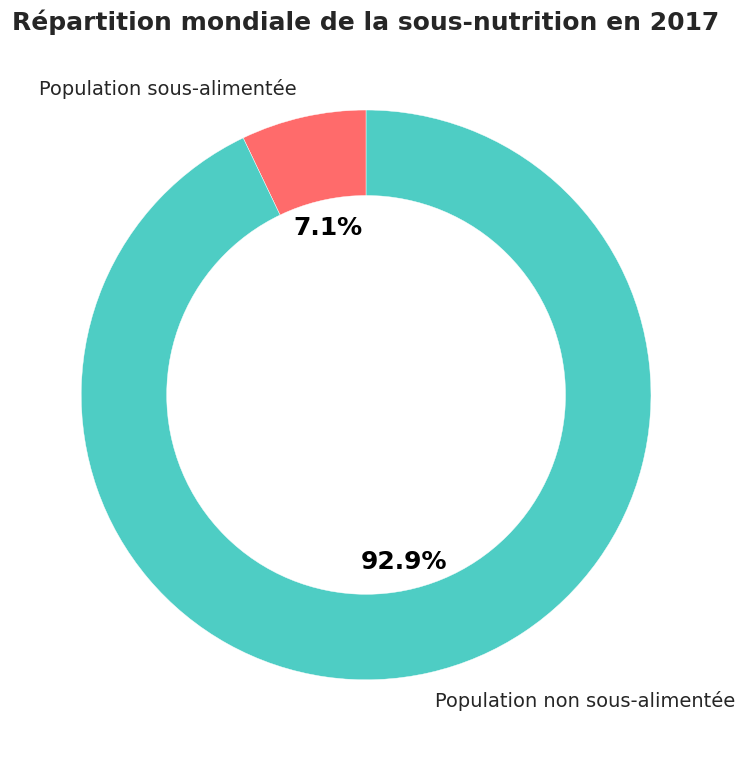

In [1105]:
# Données pour le donut
labels = ['Population sous-alimentée', 'Population non sous-alimentée']
values = [sous_alim_total, pop_totale - sous_alim_total]
colors = ['#ff6b6b', '#4ecdc4']  # rouge doux / vert doux

# Création du donut
fig, ax = plt.subplots(figsize=(8,8))

# autopct personnalisé pour augmenter la taille et mettre en gras
def autopct_format(pct):
    return f"{pct:.1f}%"  # format simple

wedges, texts, autotexts = ax.pie(
    values,
    labels=labels,
    colors=colors,
    autopct=autopct_format,
    startangle=90,
    textprops={'fontsize': 14}  # taille des labels
)

# Style des pourcentages
for autotext in autotexts:
    autotext.set_fontsize(18)   # taille plus grande
    autotext.set_fontweight('bold')  # en gras
    autotext.set_color('black')  # couleur lisible

# Cercle central pour l'effet donut
centre_circle = plt.Circle((0,0), 0.70, fc='white')
fig.gca().add_artist(centre_circle)

# Titre
plt.title("Répartition mondiale de la sous-nutrition en 2017", fontsize=18, fontweight='bold')

plt.tight_layout()
plt.show()


### 4.3 : Graphique nombre théorique de personnes nourries avec les produits végétaux

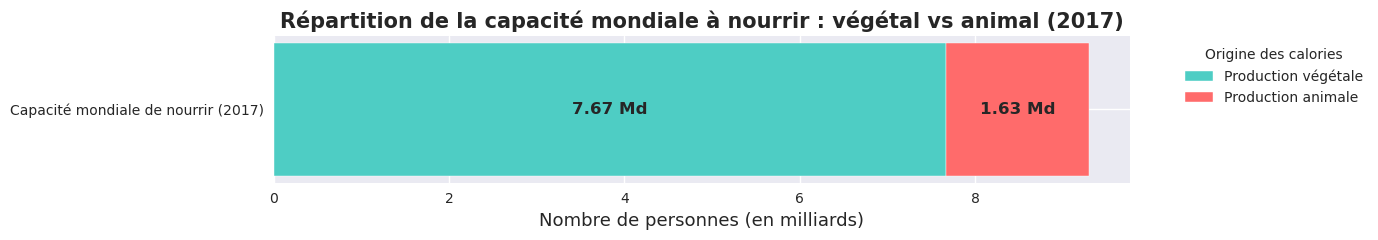

In [1106]:
# Conversion en milliards
veg_milliards = personnes_veg / 1e9
animal_milliards = diff_personnes / 1e9
total_milliards = personnes_nourries / 1e9

# Couleurs harmonisées
couleurs = ['#4ecdc4', '#ff6b6b']  # végétal / animal

plt.figure(figsize=(14,2.5))

bottom = 0

# Segment végétal
plt.barh(
    ["Capacité mondiale de nourrir (2017)"],
    veg_milliards,
    left=bottom,
    color=couleurs[0],
    label="Production végétale"
)
plt.text(
    bottom + veg_milliards/2,
    0,
    f"{veg_milliards:.2f} Md",
    ha='center',
    va='center',
    fontsize=12,
    fontweight='bold'
)
bottom += veg_milliards

# Segment animal
plt.barh(
    ["Capacité mondiale de nourrir (2017)"],
    animal_milliards,
    left=bottom,
    color=couleurs[1],
    label="Production animale"
)
plt.text(
    bottom + animal_milliards/2,
    0,
    f"{animal_milliards:.2f} Md",
    ha='center',
    va='center',
    fontsize=12,
    fontweight='bold'
)

# Titre et axes
plt.title("Répartition de la capacité mondiale à nourrir : végétal vs animal (2017)",
          fontsize=15, fontweight='bold')
plt.xlabel("Nombre de personnes (en milliards)", fontsize=13)
plt.legend(title="Origine des calories", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


### 4.4 : Graphique utilisation de la disponibilité intérieure

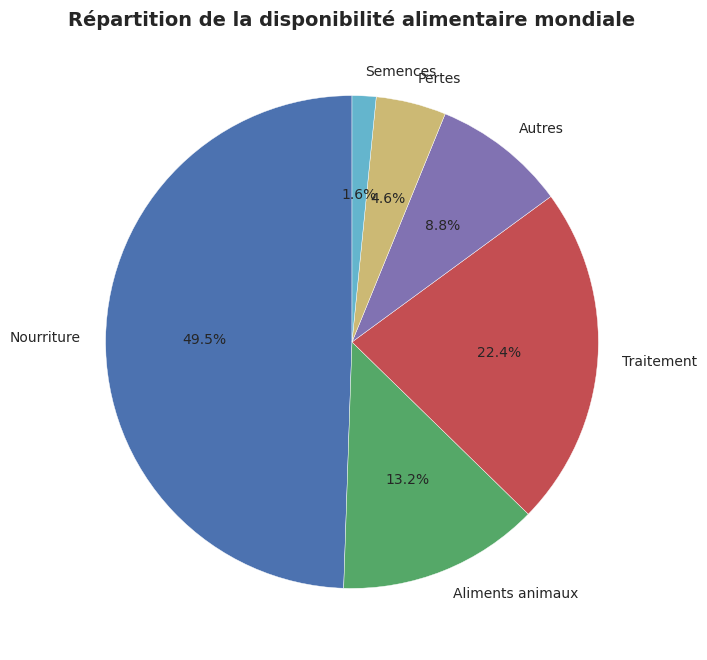

In [1107]:
labels = ['Nourriture', 'Aliments animaux', 'Traitement', 'Autres', 'Pertes', 'Semences']
sizes = [
    dispo_2017['Nourriture'].sum(),
    dispo_2017['Aliments pour animaux'].sum(),
    dispo_2017['Traitement'].sum(),
    dispo_2017['Autres Utilisations'].sum(),
    dispo_2017['Pertes'].sum(),
    dispo_2017['Semences'].sum()
]

plt.figure(figsize=(10, 8))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)
plt.title('Répartition de la disponibilité alimentaire mondiale', fontweight='bold')
plt.show()

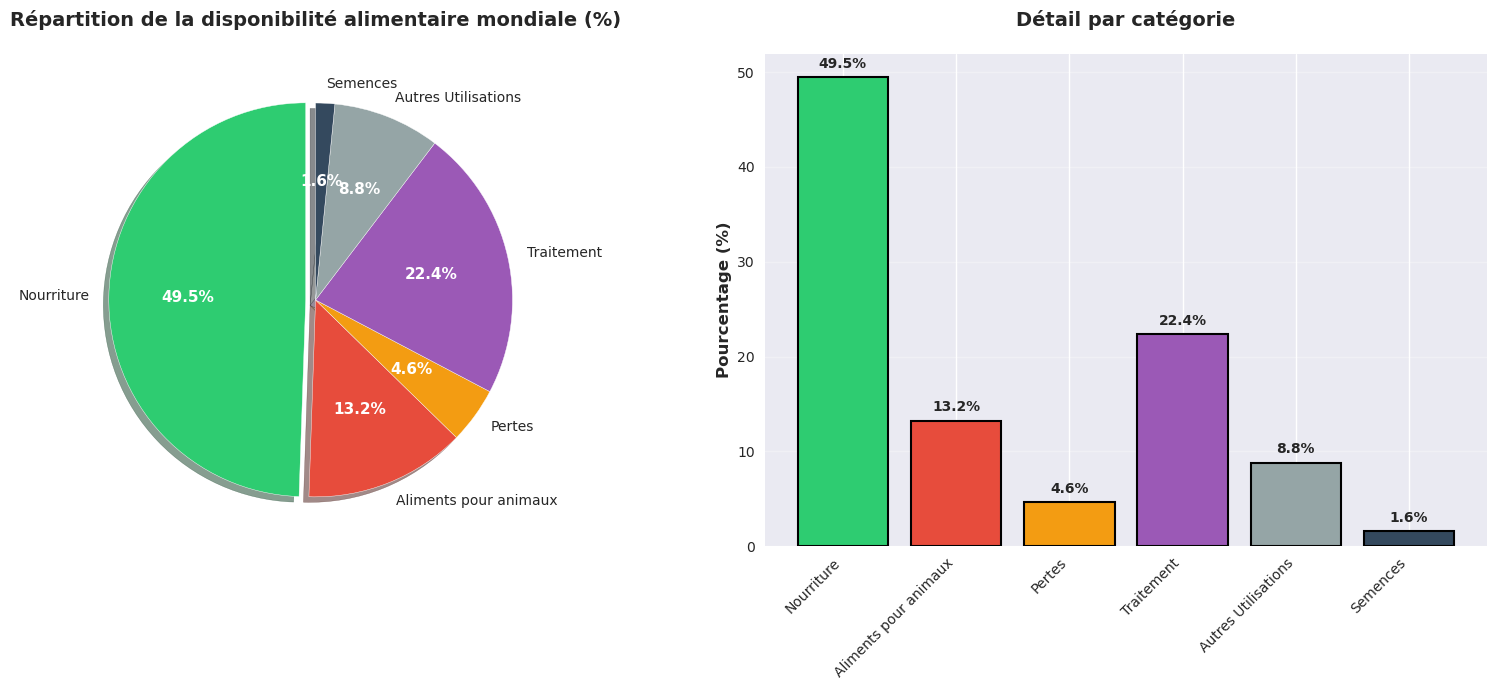

In [1108]:
# Préparer les données (calculs de la section 3.4)
colonnes_util = ['Nourriture', 'Aliments pour animaux', 'Pertes', 
                 'Traitement', 'Autres Utilisations', 'Semences']

utilisations = dispo_alimentaire[colonnes_util].sum()
utilisations_pct = (utilisations / utilisations.sum()) * 100

# Créer le graphique (diagramme circulaire)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Graphique 1 : Camembert
colors_pie = ['#2ecc71', '#e74c3c', '#f39c12', '#9b59b6', '#95a5a6', '#34495e']
wedges, texts, autotexts = ax1.pie(
    utilisations_pct,
    labels=utilisations_pct.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors_pie,
    explode=[0.05 if x == utilisations_pct.max() else 0 for x in utilisations_pct],
    shadow=True
)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(11)

ax1.set_title('Répartition de la disponibilité alimentaire mondiale (%)',
             fontsize=14, fontweight='bold', pad=20)

# Graphique 2 : Barres
ax2.bar(range(len(utilisations_pct)), utilisations_pct.values,
       color=colors_pie, edgecolor='black', linewidth=1.5)
ax2.set_xticks(range(len(utilisations_pct)))
ax2.set_xticklabels(utilisations_pct.index, rotation=45, ha='right')
ax2.set_ylabel('Pourcentage (%)', fontsize=12, fontweight='bold')
ax2.set_title('Détail par catégorie', fontsize=14, fontweight='bold', pad=20)
ax2.grid(True, alpha=0.3, axis='y')

# Annotations
for i, v in enumerate(utilisations_pct.values):
    ax2.text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


### 4.5 : Graphique utilisation des céréales

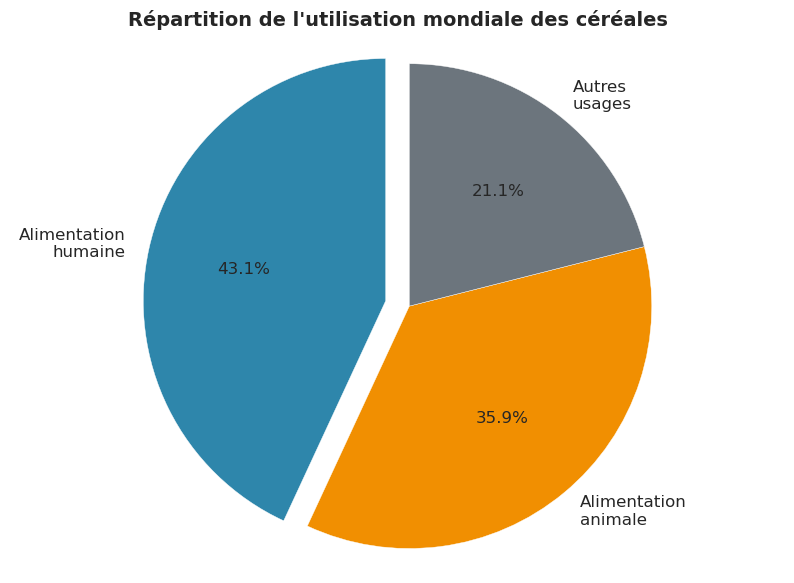

In [1109]:
labels = ['Alimentation\nhumaine', 'Alimentation\nanimale', 'Autres\nusages']
sizes = [
    nourriture_humaine,
    alim_animaux,
    total_cereales - nourriture_humaine - alim_animaux
]
colors = [COULEURS['principal'], COULEURS['accent'], COULEURS['neutre']]
explode = (0.1, 0, 0)

plt.figure(figsize=(10, 7))
plt.pie(sizes, explode=explode, labels=labels, colors=colors,
        autopct='%1.1f%%', startangle=90, textprops={'fontsize': 12})
plt.title('Répartition de l\'utilisation mondiale des céréales', 
          fontsize=14, fontweight='bold')
plt.axis('equal')
plt.show()

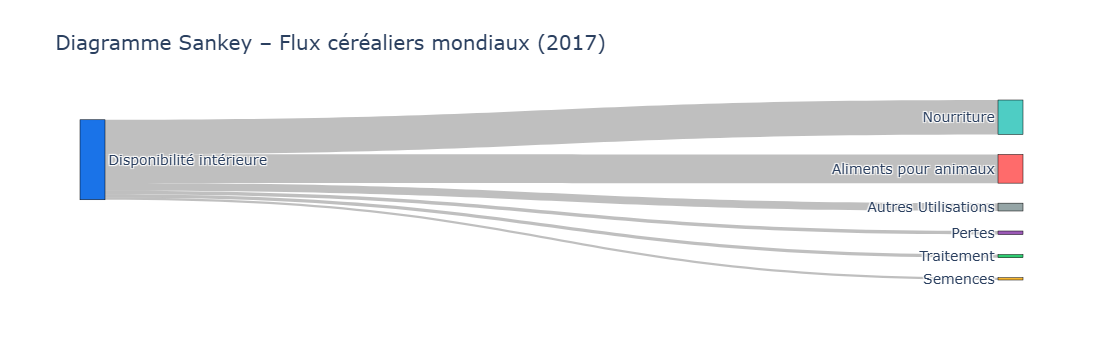

In [1110]:
import plotly.graph_objects as go

# Liste des usages
colonnes_flux = [
    'Nourriture',
    'Aliments pour animaux',
    'Semences',
    'Pertes',
    'Traitement',
    'Autres Utilisations'
]

# Colonnes existantes
colonnes_flux_existantes = [col for col in colonnes_flux if col in dispo_cereales.columns]

# Totaux par usage
flux_totaux = dispo_cereales[colonnes_flux_existantes].sum()

# Total céréales
total_cereales = flux_totaux.sum()

# Pourcentages
flux_pct = (flux_totaux / total_cereales) * 100

# Nœuds
noeuds = ["Disponibilité intérieure"] + colonnes_flux_existantes
indices = {name: i for i, name in enumerate(noeuds)}

# Sources, cibles, valeurs, labels
sources = []
targets = []
values = []
labels = []

for usage in colonnes_flux_existantes:
    sources.append(indices["Disponibilité intérieure"])
    targets.append(indices[usage])
    values.append(flux_totaux[usage])
    labels.append(f"{usage} ({flux_pct[usage]:.1f}%)")

# Création du Sankey
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=20,
        thickness=25,
        line=dict(color="black", width=0.5),
        label=noeuds,
        color=["#1a73e8"] + ["#4ecdc4", "#ff6b6b", "#f7b731", "#9b59b6", "#2ecc71", "#95a5a6"][:len(colonnes_flux_existantes)]
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        label=labels,  # ← POURCENTAGES VISIBLES DIRECTEMENT
        color="rgba(0,0,0,0.25)"
    )
)])

fig.update_layout(
    title_text="Diagramme Sankey – Flux céréaliers mondiaux (2017) ",
    font_size=14
)

fig.show()


### 4.6 : Graphique pays avec la plus forte proportion de sous nutrition en 2017

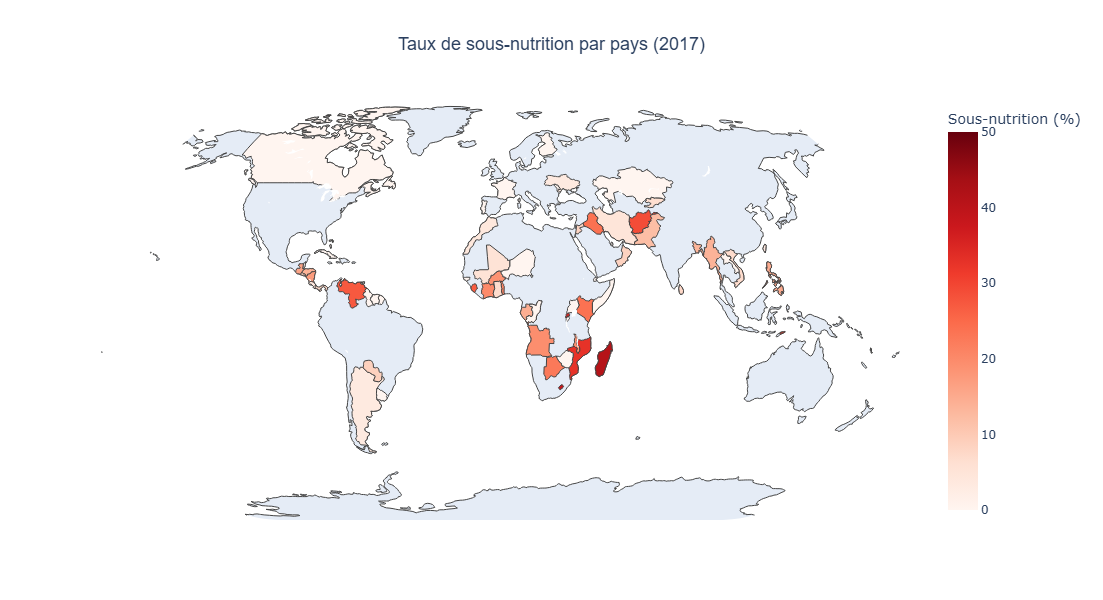

In [1111]:
# Note : Nécessite le package plotly
# Installation : pip install plotly

import plotly.express as px

# Préparer les données
data_carte = analyse_2017[['Zone', 'Proportion_sous_nutrition']].copy()
data_carte.columns = ['country', 'undernourishment']

# Créer la carte
fig = px.choropleth(
    data_carte,
    locations='country',
    locationmode='country names',
    color='undernourishment',
    color_continuous_scale='Reds',
    range_color=[0, 50],
    title='Taux de sous-nutrition par pays (2017)',
    labels={'undernourishment': 'Sous-nutrition (%)'}
)

fig.update_layout(
    title_font_size=18,
    title_font_family='Arial',
    title_x=0.5,
    geo=dict(
        showframe=False,
        showcoastlines=True,
        projection_type='natural earth'
    ),
    height=600
)

fig.show()


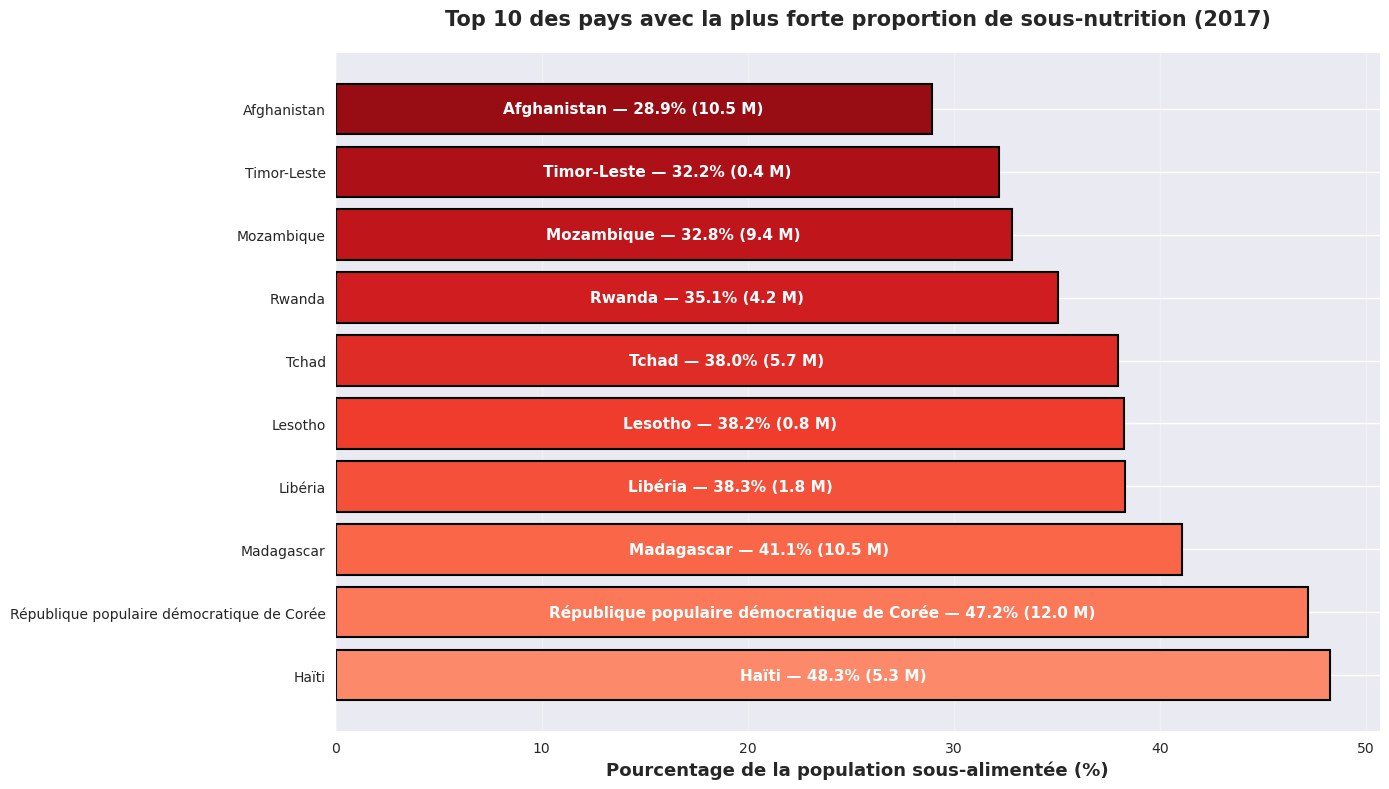

In [1112]:
# Préparer les données
top10 = analyse_2017.nlargest(10, 'Proportion_sous_nutrition')[
    ['Zone', 'Proportion_sous_nutrition', 'Sous_nutrition']
].copy()

# Créer le graphique
fig, ax = plt.subplots(figsize=(14, 8))

# Barres horizontales
colors = plt.cm.Reds(np.linspace(0.4, 0.9, len(top10)))
bars = ax.barh(
    top10['Zone'],
    top10['Proportion_sous_nutrition'],
    color=colors,
    edgecolor='black',
    linewidth=1.5
)

# Titre et axes
ax.set_xlabel('Pourcentage de la population sous-alimentée (%)',
              fontsize=13, fontweight='bold')
ax.set_title('Top 10 des pays avec la plus forte proportion de sous-nutrition (2017)',
             fontsize=15, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, axis='x')

# --- Noms + valeurs dans les barres ---
for bar, (_, row) in zip(bars, top10.iterrows()):
    width = bar.get_width()
    ax.text(
        width / 2,                                      # centre horizontal
        bar.get_y() + bar.get_height() / 2,            # centre vertical
        f"{row['Zone']} — {row['Proportion_sous_nutrition']:.1f}% ({row['Sous_nutrition']/1_000_000:.1f} M)",
        ha='center', va='center',
        fontsize=11, color='white', fontweight='bold'
    )

plt.tight_layout()
plt.show()


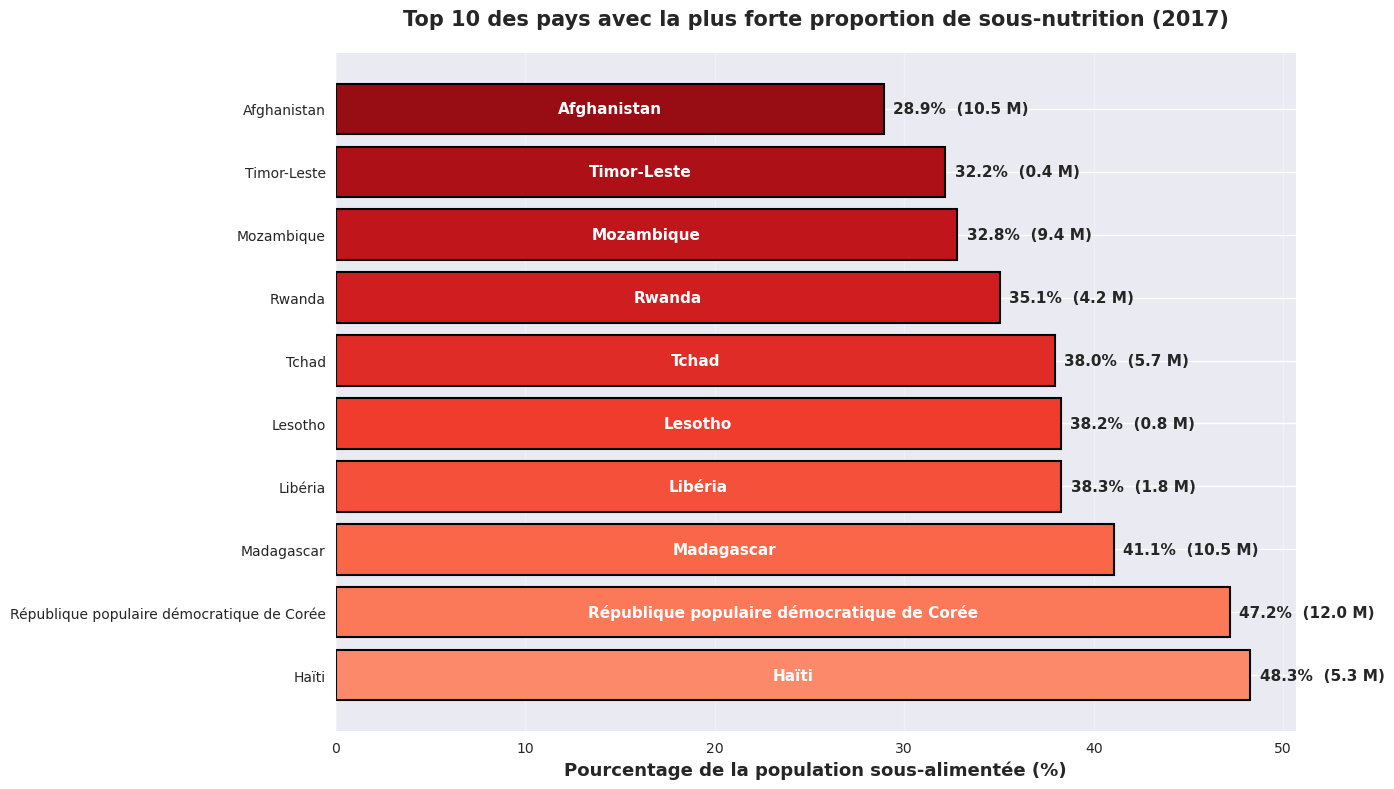

In [1113]:
# Préparer les données
top10 = analyse_2017.nlargest(10, 'Proportion_sous_nutrition')[
    ['Zone', 'Proportion_sous_nutrition', 'Sous_nutrition']
].copy()

# Créer le graphique
fig, ax = plt.subplots(figsize=(14, 8))

# Barres horizontales
colors = plt.cm.Reds(np.linspace(0.4, 0.9, len(top10)))
bars = ax.barh(
    top10['Zone'],
    top10['Proportion_sous_nutrition'],
    color=colors,
    edgecolor='black',
    linewidth=1.5
)

# Titre et axes
ax.set_xlabel('Pourcentage de la population sous-alimentée (%)',
              fontsize=13, fontweight='bold')
ax.set_title('Top 10 des pays avec la plus forte proportion de sous-nutrition (2017)',
             fontsize=15, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, axis='x')

# --- Noms des pays dans les barres ---
for bar, (_, row) in zip(bars, top10.iterrows()):
    ax.text(
        bar.get_width() / 2,                                # milieu de la barre
        bar.get_y() + bar.get_height() / 2,
        row['Zone'],                                        # nom du pays
        ha='center', va='center',
        fontsize=11, color='white', fontweight='bold'
    )

# --- Valeurs (%) + millions de personnes à droite ---
for idx, (_, row) in enumerate(top10.iterrows()):
    ax.text(
        row['Proportion_sous_nutrition'] + 0.5,             # juste à droite
        idx,
        f"{row['Proportion_sous_nutrition']:.1f}%  ({row['Sous_nutrition']/1_000_000:.1f} M)",
        va='center',
        fontsize=11,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()


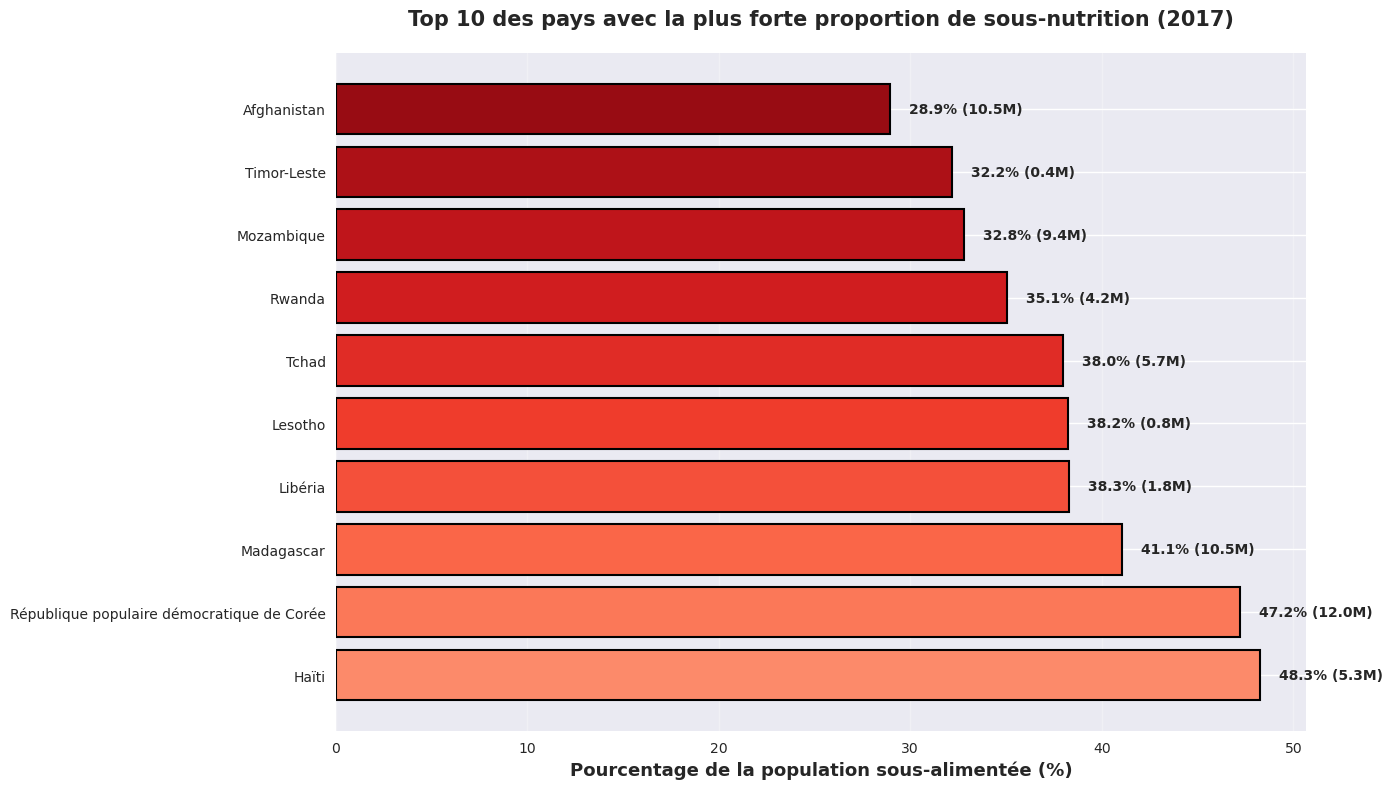

In [1114]:
# Préparer les données (utilise le DataFrame de la section 3.6)
top10 = analyse_2017.nlargest(10, 'Proportion_sous_nutrition')[
    ['Zone', 'Proportion_sous_nutrition', 'Sous_nutrition']
].copy()

# Créer le graphique
fig, ax = plt.subplots(figsize=(14, 8))

# Barres horizontales avec dégradé de couleur
colors = plt.cm.Reds(np.linspace(0.4, 0.9, len(top10)))
bars = ax.barh(top10['Zone'], top10['Proportion_sous_nutrition'], 
               color=colors, edgecolor='black', linewidth=1.5)

# Personnalisation
ax.set_xlabel('Pourcentage de la population sous-alimentée (%)', 
              fontsize=13, fontweight='bold')
ax.set_title('Top 10 des pays avec la plus forte proportion de sous-nutrition (2017)', 
             fontsize=15, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, axis='x')

# Annotations avec nombre de personnes
for idx, (_, row) in enumerate(top10.iterrows()):
    ax.text(row['Proportion_sous_nutrition'] + 1, idx,
           f"{row['Proportion_sous_nutrition']:.1f}% ({row['Sous_nutrition']/1_000_000:.1f}M)",
           va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


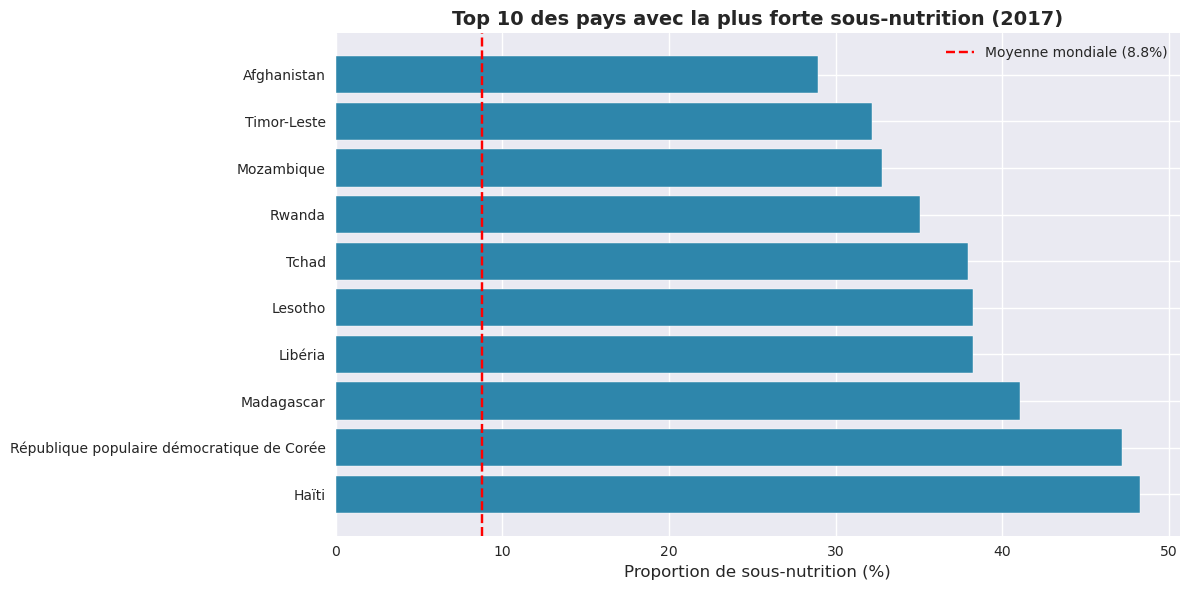

In [1115]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(
    top10_sous_alim['Zone'], 
    top10_sous_alim['Proportion_sous_nutrition'],
    color=COULEURS['principal']
)
ax.set_xlabel('Proportion de sous-nutrition (%)', fontsize=12)
ax.set_title('Top 10 des pays avec la plus forte sous-nutrition (2017)', 
             fontsize=14, fontweight='bold')
ax.axvline(x=pourcentage, color='red', linestyle='--', 
           label=f'Moyenne mondiale ({pourcentage:.1f}%)')
ax.legend()

plt.tight_layout()
plt.show()

### 4.7 : Graphique pays ayant reçu le plus d’aide alimentaire depuis 2013

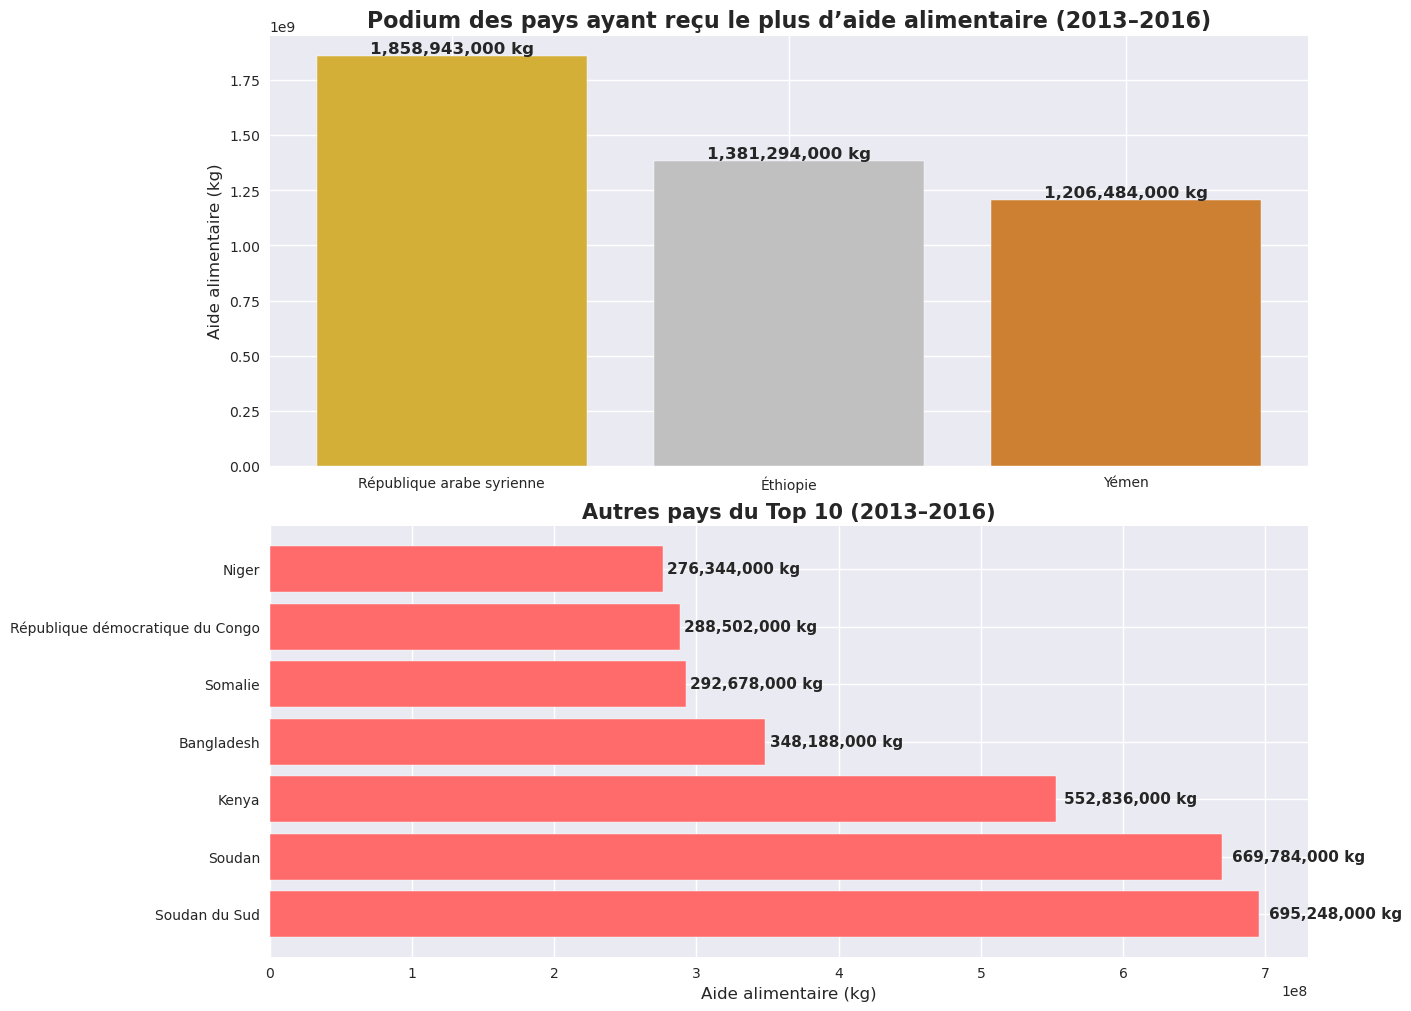

In [1116]:
# Séparation podium + autres
podium = top10_aide.head(3).copy()
autres = top10_aide.iloc[3:].copy()

# Couleurs podium
couleurs_podium = ['#D4AF37', '#C0C0C0', '#CD7F32']  # or, argent, bronze

fig = plt.figure(figsize=(14,10), constrained_layout=True)

# --- 1) PODIUM ---
ax1 = fig.add_subplot(2,1,1)
bars = ax1.bar(
    podium['Zone'],
    podium['Aide_kg'],
    color=couleurs_podium
)

# Ajout des valeurs
for bar, value in zip(bars, podium['Aide_kg']):
    ax1.text(
        bar.get_x() + bar.get_width()/2,
        value,
        f"{value:,.0f} kg",
        ha='center',
        va='bottom',
        fontsize=12,
        fontweight='bold'
    )

ax1.set_title("Podium des pays ayant reçu le plus d’aide alimentaire (2013–2016)",
              fontsize=16, fontweight='bold')
ax1.set_ylabel("Aide alimentaire (kg)")

# --- 2) TOP 10 (hors podium) ---
ax2 = fig.add_subplot(2,1,2)
bars2 = ax2.barh(
    autres['Zone'],
    autres['Aide_kg'],
    color="#ff6b6b"
)

# Ajout des valeurs
for bar, value in zip(bars2, autres['Aide_kg']):
    ax2.text(
        value + value*0.01,
        bar.get_y() + bar.get_height()/2,
        f"{value:,.0f} kg",
        va='center',
        fontsize=11,
        fontweight='bold'
    )

ax2.set_title("Autres pays du Top 10 (2013–2016)",
              fontsize=15, fontweight='bold')
ax2.set_xlabel("Aide alimentaire (kg)")

plt.show()


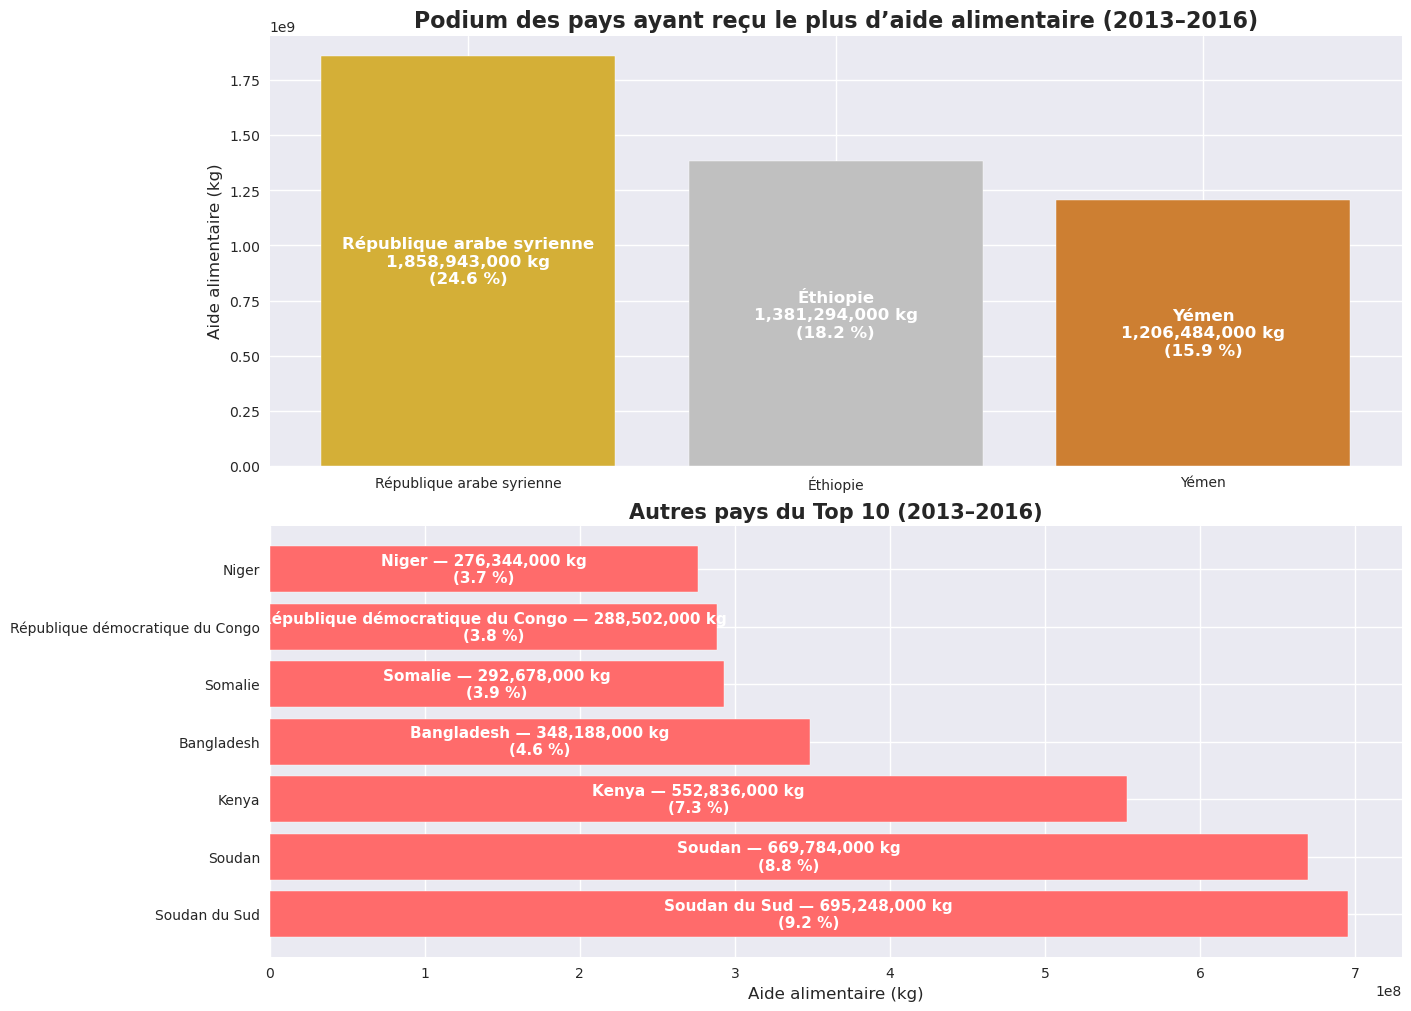

In [1117]:
# Calcul du pourcentage d'aide pour chaque pays
total_aide = top10_aide['Aide_kg'].sum()
top10_aide['Pourcentage'] = (top10_aide['Aide_kg'] / total_aide) * 100

# Séparation podium + autres
podium = top10_aide.head(3).copy()
autres = top10_aide.iloc[3:].copy()

# Couleurs podium
couleurs_podium = ['#D4AF37', '#C0C0C0', '#CD7F32']  # or, argent, bronze

fig = plt.figure(figsize=(14,10), constrained_layout=True)

# --- 1) PODIUM ---
ax1 = fig.add_subplot(2,1,1)
bars = ax1.bar(
    podium['Zone'],
    podium['Aide_kg'],
    color=couleurs_podium
)

# Ajout des noms + valeurs + pourcentage dans les barres
for bar, (_, row) in zip(bars, podium.iterrows()):
    ax1.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height()/2,
        f"{row['Zone']}\n{row['Aide_kg']:,.0f} kg\n({row['Pourcentage']:.1f} %)",
        ha='center',
        va='center',
        fontsize=12,
        fontweight='bold',
        color='white'
    )

ax1.set_title("Podium des pays ayant reçu le plus d’aide alimentaire (2013–2016)",
              fontsize=16, fontweight='bold')
ax1.set_ylabel("Aide alimentaire (kg)")

# --- 2) TOP 10 (hors podium) ---
ax2 = fig.add_subplot(2,1,2)
bars2 = ax2.barh(
    autres['Zone'],
    autres['Aide_kg'],
    color="#ff6b6b"
)

# Ajout des noms + valeurs + pourcentage dans les barres
for bar, (_, row) in zip(bars2, autres.iterrows()):
    ax2.text(
        bar.get_width()/2,
        bar.get_y() + bar.get_height()/2,
        f"{row['Zone']} — {row['Aide_kg']:,.0f} kg\n({row['Pourcentage']:.1f} %)",
        ha='center',
        va='center',
        fontsize=11,
        fontweight='bold',
        color='white'
    )

ax2.set_title("Autres pays du Top 10 (2013–2016)",
              fontsize=15, fontweight='bold')
ax2.set_xlabel("Aide alimentaire (kg)")

plt.show()


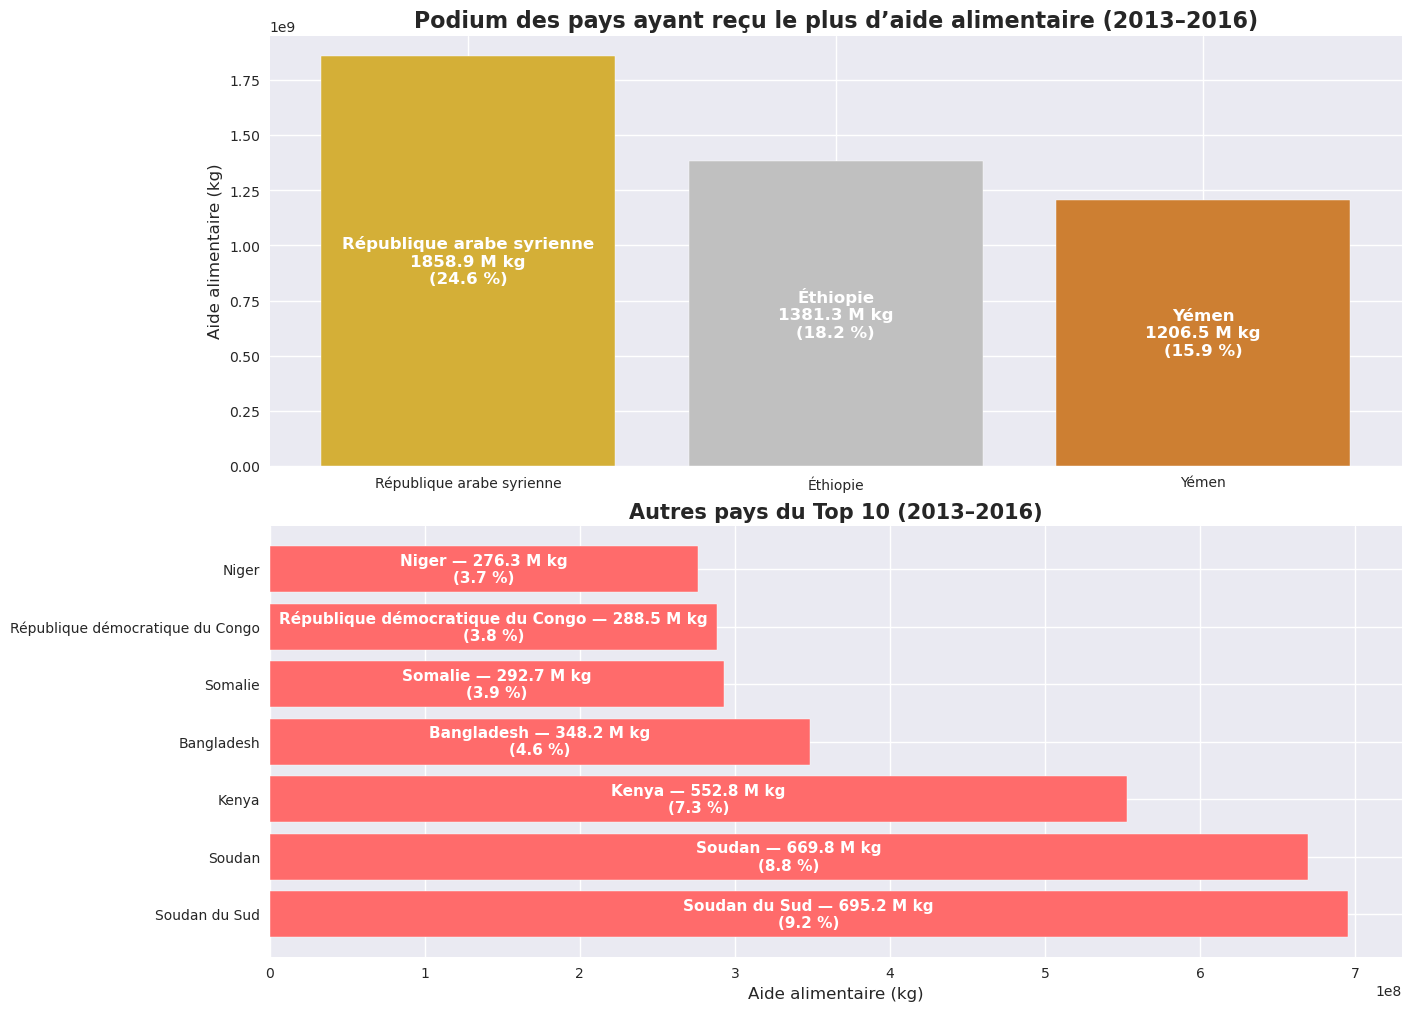

In [1118]:
# Conversion en millions
top10_aide['Aide_M'] = top10_aide['Aide_kg'] / 1_000_000

# Calcul du pourcentage d'aide pour chaque pays
total_aide = top10_aide['Aide_kg'].sum()
top10_aide['Pourcentage'] = (top10_aide['Aide_kg'] / total_aide) * 100

# Séparation podium + autres
podium = top10_aide.head(3).copy()
autres = top10_aide.iloc[3:].copy()

# Couleurs podium
couleurs_podium = ['#D4AF37', '#C0C0C0', '#CD7F32']  # or, argent, bronze

fig = plt.figure(figsize=(14,10), constrained_layout=True)

# --- 1) PODIUM ---
ax1 = fig.add_subplot(2,1,1)
bars = ax1.bar(
    podium['Zone'],
    podium['Aide_kg'],
    color=couleurs_podium
)

# Ajout des noms + valeurs en millions + pourcentage dans les barres
for bar, (_, row) in zip(bars, podium.iterrows()):
    ax1.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height()/2,
        f"{row['Zone']}\n{row['Aide_M']:.1f} M kg\n({row['Pourcentage']:.1f} %)",
        ha='center',
        va='center',
        fontsize=12,
        fontweight='bold',
        color='white'
    )

ax1.set_title("Podium des pays ayant reçu le plus d’aide alimentaire (2013–2016)",
              fontsize=16, fontweight='bold')
ax1.set_ylabel("Aide alimentaire (kg)")

# --- 2) TOP 10 (hors podium) ---
ax2 = fig.add_subplot(2,1,2)
bars2 = ax2.barh(
    autres['Zone'],
    autres['Aide_kg'],
    color="#ff6b6b"
)

# Ajout des noms + valeurs en millions + pourcentage dans les barres
for bar, (_, row) in zip(bars2, autres.iterrows()):
    ax2.text(
        bar.get_width()/2,
        bar.get_y() + bar.get_height()/2,
        f"{row['Zone']} — {row['Aide_M']:.1f} M kg\n({row['Pourcentage']:.1f} %)",
        ha='center',
        va='center',
        fontsize=11,
        fontweight='bold',
        color='white'
    )

ax2.set_title("Autres pays du Top 10 (2013–2016)",
              fontsize=15, fontweight='bold')
ax2.set_xlabel("Aide alimentaire (kg)")

plt.show()


### 4.8 : Graphique évolution des 5 pays les plus aidés (2013–2016)

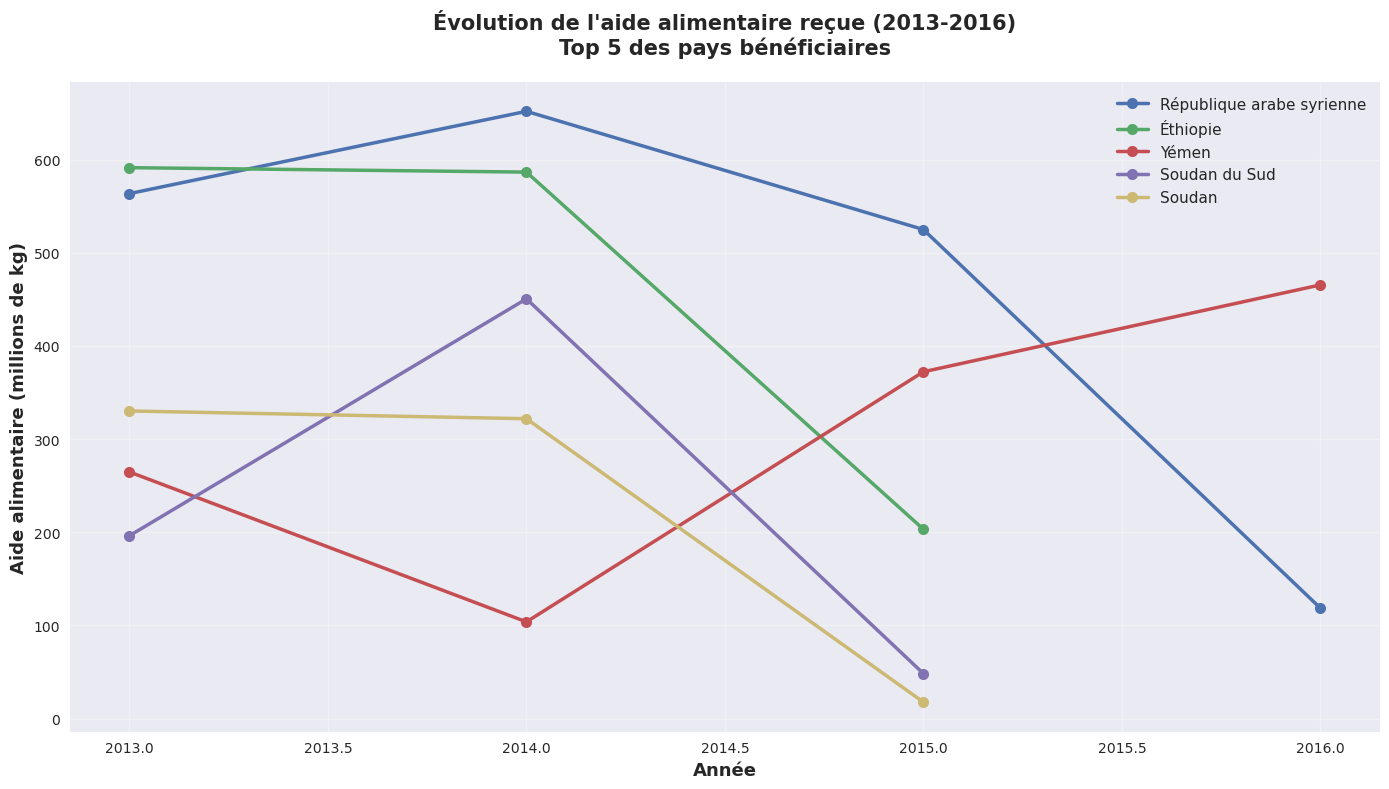

In [1119]:
# Données préparées en section 3.8
top5_pays_liste = top10_aide.head(5)['Zone'].tolist()
aide_top5 = aide_2013_2016[aide_2013_2016['Zone'].isin(top5_pays_liste)]
evolution_aide = aide_top5.groupby(['Zone', 'Année'])['Aide_kg'].sum().reset_index()

# Créer le graphique
fig, ax = plt.subplots(figsize=(14, 8))

# Une courbe par pays
for pays in top5_pays_liste:
    data_pays = evolution_aide[evolution_aide['Zone'] == pays]
    ax.plot(data_pays['Année'], data_pays['Aide_kg'] / 1_000_000,
           marker='o', linewidth=2.5, markersize=8, label=pays)

# Personnalisation
ax.set_xlabel('Année', fontsize=13, fontweight='bold')
ax.set_ylabel('Aide alimentaire (millions de kg)', fontsize=13, fontweight='bold')
ax.set_title('Évolution de l\'aide alimentaire reçue (2013-2016)\nTop 5 des pays bénéficiaires',
            fontsize=15, fontweight='bold', pad=20)
ax.legend(loc='best', fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### 4.9 : Graphique pays avec le moins de disponibilité alimentaire par habitant

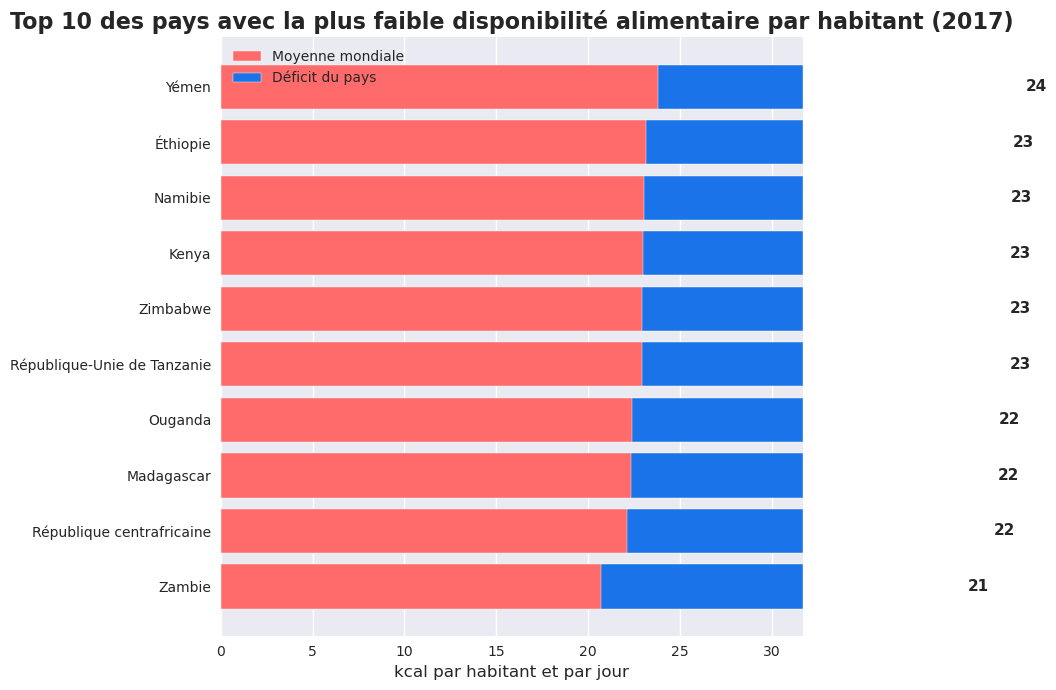

In [1120]:
# Sélection des 10 pays les plus faibles
bottom10 = dispo_analyse.nsmallest(10, col_kcal).copy()

# Moyenne mondiale
moyenne_monde = dispo_pop[col_kcal].mean()

# Données
pays = bottom10['Zone']
valeurs = bottom10[col_kcal]
deficit = valeurs - moyenne_monde  # valeurs négatives

plt.figure(figsize=(12,7))

# Barre moyenne mondiale (base)
plt.barh(
    pays,
    [moyenne_monde]*len(pays),
    color="#ff6b6b",
    label="Moyenne mondiale"
)

# Barre déficit (négatif)
plt.barh(
    pays,
    deficit,
    left=[moyenne_monde]*len(pays),
    color="#1a73e8",
    label="Déficit du pays"
)

# Ajout des valeurs
for i, v in enumerate(valeurs):
    plt.text(
        v + 20,
        i,
        f"{v:.0f}",
        va='center',
        fontsize=11,
        fontweight='bold'
    )

plt.title("Top 10 des pays avec la plus faible disponibilité alimentaire par habitant (2017)",
          fontsize=16, fontweight='bold')
plt.xlabel("kcal par habitant et par jour")
plt.legend()
plt.tight_layout()
plt.show()


### 4.10 : Graphique pays avec le plus de disponibilité alimentaire par habitant

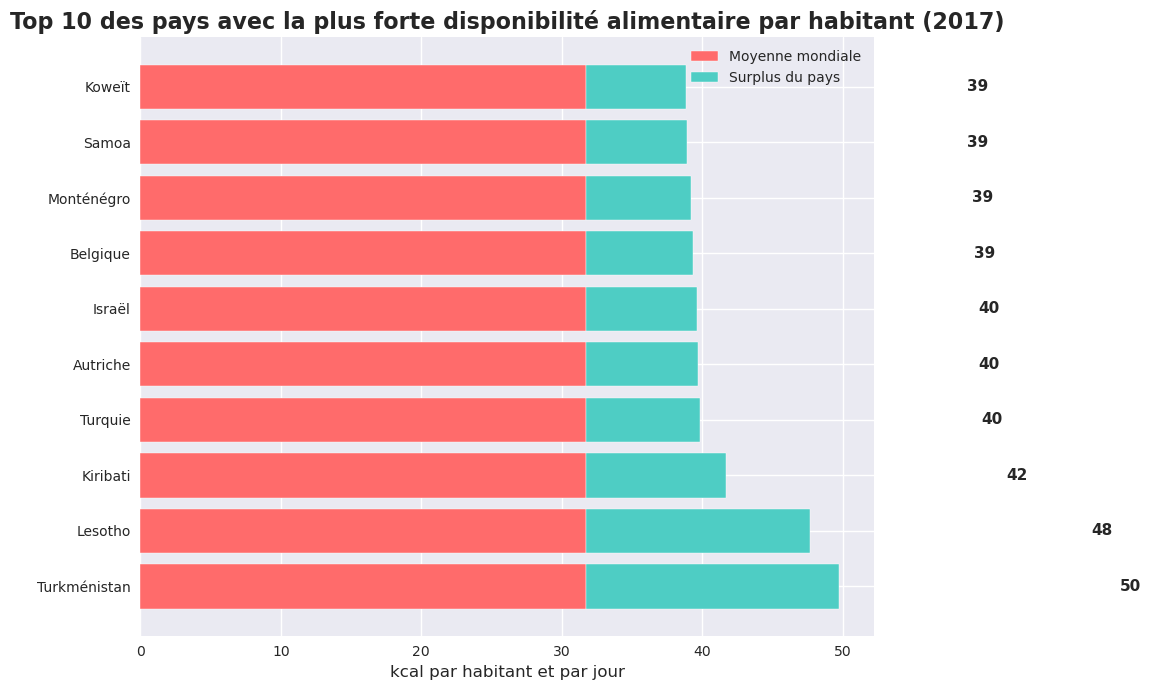

In [1121]:
top10 = top10_dispo.copy()
moyenne_monde = dispo_pop[col_kcal].mean()

pays = top10['Zone']
valeurs = top10[col_kcal]
surplus = valeurs - moyenne_monde

plt.figure(figsize=(12,7))

plt.barh(
    pays,
    [moyenne_monde]*len(pays),
    color="#ff6b6b",
    label="Moyenne mondiale"
)

plt.barh(
    pays,
    surplus,
    left=[moyenne_monde]*len(pays),
    color="#4ecdc4",
    label="Surplus du pays"
)

# Valeurs
for i, v in enumerate(valeurs):
    plt.text(
        v + 20,
        i,
        f"{v:.0f}",
        va='center',
        fontsize=11,
        fontweight='bold'
    )

plt.title("Top 10 des pays avec la plus forte disponibilité alimentaire par habitant (2017)",
          fontsize=16, fontweight='bold')
plt.xlabel("kcal par habitant et par jour")
plt.legend()
plt.tight_layout()
plt.show()

